In [1]:
# Step 1 — Import libraries and load the dataset
import pandas as pd
import numpy as np

df = pd.read_csv("../data/processed/final/churn_model_data.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset Shape: (6260, 73)

Columns:
['customer_id', 'age', 'gender', 'country', 'city', 'acquisition_channel', 'customer_segment', 'preferred_language', 'tenure_days', 'total_viewing_sessions', 'total_watch_duration_minutes', 'average_watch_duration_minutes', 'average_completion_percentage', 'average_session_duration_minutes', 'unique_content_watched', 'active_viewing_days', 'days_since_last_viewing', 'has_viewing_activity', 'total_support_tickets', 'unique_issue_categories', 'most_common_issue_category', 'has_support_activity', 'total_payment_transactions', 'successful_payment_count', 'failed_payment_count', 'total_amount_paid', 'average_successful_payment_amount', 'payment_success_rate', 'unique_payment_methods', 'most_used_payment_method', 'days_since_last_successful_payment', 'has_successful_payment', 'total_feedback_count', 'average_feedback_rating', 'positive_feedback_count', 'neutral_feedback_count', 'negative_feedback_count', 'negative_feedback_rate', 'latest_feedback_rating', 

In [2]:
# Step 2 — Inspect payment and subscription information
payment_columns = [
    "total_payment_transactions",
    "successful_payment_count",
    "failed_payment_count",
    "total_amount_paid",
    "average_successful_payment_amount",
    "payment_success_rate",
    "monthly_price_asof",
    "tenure_days",
    "subscription_tenure_days_asof",
    "churned"
]

display(df[payment_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
total_payment_transactions,6260.0,13.844089,3.162071,1.0000,15.000000,15.000000,15.00,15.0000
successful_payment_count,6260.0,13.008626,3.125166,0.0000,13.000000,14.000000,15.00,15.0000
failed_payment_count,6260.0,0.835463,0.973899,0.0000,0.000000,1.000000,1.00,8.0000
total_amount_paid,6260.0,181.044243,100.071905,0.0000,97.860000,185.880000,232.35,629.9300
average_successful_payment_amount,6253.0,13.857318,6.653853,5.2425,6.990000,15.490000,15.49,51.7275
payment_success_rate,6260.0,0.939340,0.078059,0.0000,0.933333,0.933333,1.00,1.0000
monthly_price_asof,6260.0,13.509249,6.135752,6.9900,6.990000,15.490000,15.49,22.9900
tenure_days,6260.0,1365.726358,777.850061,0.0000,699.750000,1375.000000,2026.00,2707.0000
subscription_tenure_days_asof,6260.0,1291.052236,788.430646,0.0000,600.000000,1287.500000,1954.00,2707.0000


In [3]:
# Step 3 — Identify all CSV files
import os

for root, dirs, files in os.walk("../data"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

../data\processed\churn_labels_clean.csv
../data\processed\churn_labels_cleaning_log.csv
../data\processed\content_clean.csv
../data\processed\content_cleaning_log.csv
../data\processed\customers_clean.csv
../data\processed\customer_cleaning_log.csv
../data\processed\customer_feedback_clean.csv
../data\processed\customer_feedback_cleaning_log.csv
../data\processed\payments_ambiguous.csv
../data\processed\payments_clean.csv
../data\processed\payments_cleaning_log.csv
../data\processed\payments_matched.csv
../data\processed\payments_reconciliation_audit.csv
../data\processed\payments_reconciliation_summary.csv
../data\processed\payments_unmatched.csv
../data\processed\subscriptions_clean.csv
../data\processed\subscriptions_cleaning_log.csv
../data\processed\subscription_plans_clean.csv
../data\processed\support_tickets_clean.csv
../data\processed\support_tickets_cleaning_log.csv
../data\processed\viewing_activity_clean.csv
../data\processed\viewing_activity_cleaning_log.csv
../data\proce

In [4]:
# Step 4 — Load and inspect payment and subscription data
payments = pd.read_csv("../data/processed/payments_clean.csv")
subscriptions = pd.read_csv("../data/processed/subscriptions_clean.csv")

print("PAYMENTS DATA")
print("Shape:", payments.shape)
print("Columns:", payments.columns.tolist())
display(payments.head())

print("\nSUBSCRIPTIONS DATA")
print("Shape:", subscriptions.shape)
print("Columns:", subscriptions.columns.tolist())
display(subscriptions.head())

PAYMENTS DATA
Shape: (110735, 8)
Columns: ['payment_id', 'customer_id', 'subscription_id', 'payment_date', 'amount', 'payment_method', 'payment_status', 'failed_payment_reason']


,payment_id,customer_id,subscription_id,payment_date,amount,payment_method,payment_status,failed_payment_reason
0,PAY00000001,CUST000001,SUB0000001,2022-04-30,22.99,Debit Card,Success,NaN
1,PAY00000002,CUST000001,SUB0000001,2022-05-30,22.99,Net Banking,Success,NaN
2,PAY00000003,CUST000001,SUB0000001,2022-06-29,22.99,Debit Card,Success,NaN
3,PAY00000004,CUST000001,SUB0000001,2022-07-29,22.99,Debit Card,Success,NaN
4,PAY00000005,CUST000001,SUB0000001,2022-08-28,22.99,PayPal,Success,NaN



SUBSCRIPTIONS DATA
Shape: (8875, 10)
Columns: ['subscription_id', 'customer_id', 'plan_id', 'subscription_start_date', 'subscription_end_date', 'subscription_status', 'auto_renew', 'cancellation_date', 'cancellation_reason', 'monthly_price']


,subscription_id,customer_id,plan_id,subscription_start_date,subscription_end_date,subscription_status,auto_renew,cancellation_date,cancellation_reason,monthly_price
0,SUB0000001,CUST000001,PLAN03,2022-04-30,NaN,Active,True,NaN,NaN,22.99
1,SUB0000002,CUST000002,PLAN02,2025-12-24,NaN,Active,True,NaN,NaN,15.49
2,SUB0000003,CUST000003,PLAN03,2019-12-15,2026-04-20,Cancelled,True,2026-04-20,Too expensive,22.99
3,SUB0000004,CUST000004,PLAN01,2019-01-28,NaN,Active,False,NaN,NaN,6.99
4,SUB0000005,CUST000005,PLAN01,2024-07-24,NaN,Active,True,NaN,NaN,6.99


In [5]:
# Step 5 — Check date ranges and data coverage
date_columns = {
    "Payments": ["payment_date"],
    "Subscriptions": [
        "subscription_start_date",
        "subscription_end_date",
        "cancellation_date"
    ]
}

for dataset_name, columns in date_columns.items():
    dataset = payments if dataset_name == "Payments" else subscriptions

    print(f"\n{dataset_name} DATE RANGE")

    for column in columns:
        dataset[column] = pd.to_datetime(dataset[column], errors="coerce")
        print(
            column,
            "| Earliest:", dataset[column].min(),
            "| Latest:", dataset[column].max(),
            "| Missing:", dataset[column].isna().sum()
        )

print("\nPAYMENT STATUS")
display(payments["payment_status"].value_counts(dropna=False))

print("\nSUBSCRIPTION STATUS")
display(subscriptions["subscription_status"].value_counts(dropna=False))

print("\nUNIQUE CUSTOMERS")
print("Payments:", payments["customer_id"].nunique())
print("Subscriptions:", subscriptions["customer_id"].nunique())


Payments DATE RANGE
payment_date | Earliest: 2019-01-01 00:00:00 | Latest: 2026-05-31 00:00:00 | Missing: 0

Subscriptions DATE RANGE
subscription_start_date | Earliest: 2019-01-01 00:00:00 | Latest: 2026-06-29 00:00:00 | Missing: 0
subscription_end_date | Earliest: 2019-04-11 00:00:00 | Latest: 2026-06-30 00:00:00 | Missing: 6051
cancellation_date | Earliest: 2025-10-03 00:00:00 | Latest: 2026-06-30 00:00:00 | Missing: 6884

PAYMENT STATUS


payment_status
Success    103529
Failed       7206
Name: count, dtype: int64


SUBSCRIPTION STATUS


subscription_status
Active          6009
Cancelled       1991
Plan Changed     875
Name: count, dtype: int64


UNIQUE CUSTOMERS
Payments: 8000
Subscriptions: 8000


In [6]:
# Step 6 — Inspect payment and subscription records around the cutoff
print("PAYMENTS BY YEAR")
display(payments["payment_date"].dt.year.value_counts().sort_index())

print("\nPAYMENTS IN 2026")
display(
    payments[
        payments["payment_date"].between("2026-01-01", "2026-05-31")
    ]["payment_status"].value_counts()
)

print("\nSUBSCRIPTIONS STARTED IN 2026")
display(
    subscriptions[
        subscriptions["subscription_start_date"].dt.year == 2026
    ]["subscription_status"].value_counts()
)

print("\nSUBSCRIPTIONS CANCELLED IN 2026")
display(
    subscriptions[
        subscriptions["cancellation_date"].dt.year == 2026
    ]["subscription_status"].value_counts()
)

PAYMENTS BY YEAR


payment_date
2019     6810
2020    15579
2021    16001
2022    16512
2023    16557
2024    16353
2025    16293
2026     6630
Name: count, dtype: int64


PAYMENTS IN 2026


payment_status
Success    6207
Failed      423
Name: count, dtype: int64


SUBSCRIPTIONS STARTED IN 2026


subscription_status
Active       447
Cancelled    194
Name: count, dtype: int64


SUBSCRIPTIONS CANCELLED IN 2026


subscription_status
Cancelled    1380
Name: count, dtype: int64

In [7]:
# Step 7 — Check the final payment observation date
print("Latest successful payment:")
print(payments.loc[payments["payment_status"] == "Success","payment_date"].max())

print("\nEarliest successful payment:")
print(payments.loc[payments["payment_status"] == "Success","payment_date"].min())

print("\nSuccessful payments after May 31, 2025:")
display(payments[(payments["payment_status"] == "Success") &(payments["payment_date"] > "2025-05-31")].groupby(payments["payment_date"].dt.year)["amount"].agg(
        ["count", "sum"]
    )
)

Latest successful payment:
2026-05-31 00:00:00

Earliest successful payment:
2019-01-01 00:00:00

Successful payments after May 31, 2025:


,count,sum
payment_date,,
2025,8916,124259.43
2026,6207,87667.66


In [8]:
# Step 8 — Check historical customer coverage
cutoff_date = pd.Timestamp("2024-05-31")
target_start = pd.Timestamp("2024-06-01")
target_end = pd.Timestamp("2025-05-31")

historical_payments = payments[
    payments["payment_date"] <= cutoff_date
]

future_payments = payments[
    (payments["payment_date"] >= target_start) &
    (payments["payment_date"] <= target_end) &
    (payments["payment_status"] == "Success")
]

print("Historical customers:", historical_payments["customer_id"].nunique())
print("Customers with future successful payments:", future_payments["customer_id"].nunique())
print("Future successful payment transactions:", len(future_payments))
print("Future successful payment amount:", future_payments["amount"].sum())
print("Future observation period:", target_start.date(), "to", target_end.date())

Historical customers: 5830
Customers with future successful payments: 2316
Future successful payment transactions: 15357
Future successful payment amount: 210054.0
Future observation period: 2024-06-01 to 2025-05-31


In [9]:
# Step 9 — Build the future revenue target
future_revenue = (
    future_payments
    .groupby("customer_id")["amount"]
    .sum()
    .reset_index()
)

future_revenue.rename(
    columns={"amount": "future_revenue_12m"},
    inplace=True
)

clv_target = historical_payments[
    ["customer_id"]
].drop_duplicates()

clv_target = clv_target.merge(
    future_revenue,
    on="customer_id",
    how="left"
)

clv_target["future_revenue_12m"] = (
    clv_target["future_revenue_12m"].fillna(0)
)

print("Target dataset shape:", clv_target.shape)
print("\nFuture revenue summary:")
display(clv_target["future_revenue_12m"].describe())

print("\nCustomers with zero future revenue:",
      (clv_target["future_revenue_12m"] == 0).sum())

print("Customers with positive future revenue:",
      (clv_target["future_revenue_12m"] > 0).sum())

Target dataset shape: (5830, 2)

Future revenue summary:


count    5830.000000
mean       19.862407
std        50.460533
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       528.770000
Name: future_revenue_12m, dtype: float64


Customers with zero future revenue: 4597
Customers with positive future revenue: 1233


In [10]:
# Step 10 — Verify customer overlap
historical_customer_ids = set(historical_payments["customer_id"])
future_customer_ids = set(future_payments["customer_id"])

print("Historical customers:", len(historical_customer_ids))
print("Future-paying customers:", len(future_customer_ids))
print("Customers present in both periods:", len(historical_customer_ids & future_customer_ids))
print("Future-paying customers not in historical cohort:", len(future_customer_ids - historical_customer_ids))
print("Historical customers without future payments:", len(historical_customer_ids - future_customer_ids))

Historical customers: 5830
Future-paying customers: 2316
Customers present in both periods: 1233
Future-paying customers not in historical cohort: 1083
Historical customers without future payments: 4597


In [11]:
# Step 11 — Check subscription coverage at the cutoff
historical_subscriptions = subscriptions[subscriptions["subscription_start_date"] <= cutoff_date
].copy()

historical_subscriptions["active_at_cutoff"] = (
    historical_subscriptions["subscription_start_date"].le(cutoff_date) &
    (
        historical_subscriptions["subscription_end_date"].isna() |
        historical_subscriptions["subscription_end_date"].gt(cutoff_date)
    ) &
    (
        historical_subscriptions["cancellation_date"].isna() |
        historical_subscriptions["cancellation_date"].gt(cutoff_date)
    )
)

print("Historical subscriptions:", len(historical_subscriptions))
print("Unique historical customers:", historical_subscriptions["customer_id"].nunique())

print("\nSubscription status at May 31, 2024:")
display(historical_subscriptions["active_at_cutoff"].value_counts())

print("\nSubscription status:")
display(historical_subscriptions["subscription_status"].value_counts())

Historical subscriptions: 6165
Unique historical customers: 5830

Subscription status at May 31, 2024:


active_at_cutoff
True     5830
False     335
Name: count, dtype: int64


Subscription status:


subscription_status
Active          4233
Cancelled       1268
Plan Changed     664
Name: count, dtype: int64

In [12]:
# Step 12 — Verify active customers
active_subscriptions = historical_subscriptions[
    historical_subscriptions["active_at_cutoff"]
]

active_customer_ids = active_subscriptions["customer_id"].unique()

print("Active subscription records:", len(active_subscriptions))
print("Unique active customers:", len(active_customer_ids))
print("Historical cohort customers:", historical_subscriptions["customer_id"].nunique())

print("\nCustomers without an active subscription:")
print(
    historical_subscriptions["customer_id"].nunique()
    - len(active_customer_ids)
)

Active subscription records: 5830
Unique active customers: 5830
Historical cohort customers: 5830

Customers without an active subscription:
0


In [13]:
# Step 13 — Check future subscription activity
future_subscriptions = subscriptions[
    (subscriptions["customer_id"].isin(active_customer_ids)) &
    (
        (subscriptions["subscription_start_date"] >= target_start) &
        (subscriptions["subscription_start_date"] <= target_end)
    )
].copy()

print("New subscriptions during future period:", len(future_subscriptions))

print("\nSubscription status:")
display(future_subscriptions["subscription_status"].value_counts())

print("\nUnique customers with new subscriptions:",
      future_subscriptions["customer_id"].nunique())

print("\nCancellations during future period:")
print(
    subscriptions[
        (subscriptions["customer_id"].isin(active_customer_ids)) &
        (subscriptions["cancellation_date"] >= target_start) &
        (subscriptions["cancellation_date"] <= target_end)
    ]["customer_id"].nunique()
)

New subscriptions during future period: 165

Subscription status:


subscription_status
Active       117
Cancelled     48
Name: count, dtype: int64


Unique customers with new subscriptions: 165

Cancellations during future period:
0


In [14]:
# Step 14 — Check payment activity for the eligible cohort
cohort_ids = set(active_customer_ids)

cohort_payments = payments[
    payments["customer_id"].isin(cohort_ids)
].copy()

historical_successful = cohort_payments[
    (cohort_payments["payment_date"] <= cutoff_date) &
    (cohort_payments["payment_status"] == "Success")
]

future_successful = cohort_payments[
    (cohort_payments["payment_date"] >= target_start) &
    (cohort_payments["payment_date"] <= target_end) &
    (cohort_payments["payment_status"] == "Success")
]

print("Historical successful transactions:", len(historical_successful))
print("Historical successful payment amount:", historical_successful["amount"].sum())

print("\nFuture successful transactions:", len(future_successful))
print("Future successful payment amount:", future_successful["amount"].sum())

print("\nCustomers with historical successful payments:",
      historical_successful["customer_id"].nunique())

print("Customers with future successful payments:",
      future_successful["customer_id"].nunique())

Historical successful transactions: 73049
Historical successful payment amount: 1008530.2399999999

Future successful transactions: 8473
Future successful payment amount: 115797.83

Customers with historical successful payments: 5822
Customers with future successful payments: 1233


In [15]:
# Step 15 — Identify customers without historical successful payments
historical_customer_ids = set(historical_successful["customer_id"])
cohort_customer_ids = set(cohort_ids)

customers_without_historical_payments = (
    cohort_customer_ids - historical_customer_ids
)

print("Customers without historical successful payments:",
      len(customers_without_historical_payments))

display(
    cohort_payments[
        cohort_payments["customer_id"].isin(
            customers_without_historical_payments
        )
    ].sort_values(["customer_id", "payment_date"])
)

Customers without historical successful payments: 8


,payment_id,customer_id,subscription_id,payment_date,amount,payment_method,payment_status,failed_payment_reason
9288,PAY00009289,CUST000676,SUB0000742,2024-05-02,6.99,Debit Card,Failed,Card reported lost/stolen
9289,PAY00009290,CUST000676,SUB0000742,2024-06-01,6.99,PayPal,Success,NaN
9290,PAY00009291,CUST000676,SUB0000742,2024-07-01,6.99,Debit Card,Success,NaN
9291,PAY00009292,CUST000676,SUB0000742,2024-07-31,6.99,Credit Card,Success,NaN
9292,PAY00009293,CUST000676,SUB0000742,2024-08-30,6.99,Credit Card,Success,NaN
...,...,...,...,...,...,...,...,...
102368,PAY00102369,CUST007394,SUB0008198,2025-03-06,6.99,Debit Card,Failed,Insufficient funds
102369,PAY00102370,CUST007394,SUB0008198,2025-04-05,6.99,UPI,Success,NaN
102370,PAY00102371,CUST007394,SUB0008198,2025-05-05,6.99,Debit Card,Success,NaN
102371,PAY00102372,CUST007394,SUB0008198,2025-06-04,6.99,Credit Card,Success,NaN


In [16]:
# Step 16 — Verify the eight customers' payment history
customer_payment_check = (
    cohort_payments[
        cohort_payments["customer_id"].isin(
            customers_without_historical_payments
        )
    ]
    .groupby("customer_id")
    .agg(
        total_transactions=("payment_id", "count"),
        successful_payments=("payment_status", lambda x: (x == "Success").sum()),
        failed_payments=("payment_status", lambda x: (x == "Failed").sum()),
        first_payment_date=("payment_date", "min"),
        first_successful_payment=("payment_date", lambda x: x[
            cohort_payments.loc[x.index, "payment_status"].eq("Success")
        ].min())
    )
    .reset_index()
)

display(customer_payment_check)

,customer_id,total_transactions,successful_payments,failed_payments,first_payment_date,first_successful_payment
0,CUST000676,15,9,6,2024-05-02,2024-06-01
1,CUST001428,15,12,3,2024-05-17,2024-07-16
2,CUST003001,15,14,1,2024-05-23,2024-06-22
3,CUST004327,15,14,1,2024-05-15,2024-06-14
4,CUST004988,15,13,2,2024-04-13,2024-06-12
5,CUST005214,15,14,1,2024-05-13,2024-06-12
6,CUST007040,15,14,1,2024-05-25,2024-06-24
7,CUST007394,15,13,2,2024-05-10,2024-06-09


In [17]:
# Step 17 — Build historical payment features
historical_payment_features = (
    historical_payments
    .groupby("customer_id")
    .agg(
        historical_payment_transactions=("payment_id", "count"),
        historical_successful_payments=("payment_status", lambda x: (x == "Success").sum()),
        historical_failed_payments=("payment_status", lambda x: (x == "Failed").sum()),
        historical_revenue=("amount", lambda x: x[
            historical_payments.loc[x.index, "payment_status"].eq("Success")
        ].sum()),
        historical_avg_payment=("amount", lambda x: x[
            historical_payments.loc[x.index, "payment_status"].eq("Success")
        ].mean()),
        last_payment_date=("payment_date", "max")
    )
    .reset_index()
)

historical_payment_features["days_since_last_payment"] = (
    cutoff_date - historical_payment_features["last_payment_date"]
).dt.days

display(historical_payment_features.head())
print("Feature dataset shape:", historical_payment_features.shape)

,customer_id,historical_payment_transactions,historical_successful_payments,historical_failed_payments,historical_revenue,historical_avg_payment,last_payment_date,days_since_last_payment
0,CUST000001,15,15,0,333.35,22.223333,2023-06-24,342
1,CUST000003,15,15,0,344.85,22.990000,2021-02-07,1209
2,CUST000004,15,14,1,97.86,6.990000,2020-03-23,1530
3,CUST000008,10,10,0,154.90,15.490000,2024-05-17,14
4,CUST000009,15,13,2,185.88,14.298462,2021-01-11,1236


Feature dataset shape: (5830, 8)


In [18]:
# Step 18 — Validate historical payment features
print("Dataset shape:", historical_payment_features.shape)

print("\nMissing values:")
display(historical_payment_features.isnull().sum())

print("\nDuplicate customer IDs:",
      historical_payment_features["customer_id"].duplicated().sum())

print("\nPayment feature summary:")
display(
    historical_payment_features[
        [
            "historical_payment_transactions",
            "historical_successful_payments",
            "historical_failed_payments",
            "historical_revenue",
            "historical_avg_payment",
            "days_since_last_payment"
        ]
    ].describe().T
)

Dataset shape: (5830, 8)

Missing values:


customer_id                        0
historical_payment_transactions    0
historical_successful_payments     0
historical_failed_payments         0
historical_revenue                 0
historical_avg_payment             8
last_payment_date                  0
days_since_last_payment            0
dtype: int64


Duplicate customer IDs: 0

Payment feature summary:


,count,mean,std,min,25%,50%,75%,max
historical_payment_transactions,5830.0,13.406346,3.577065,1.00,15.00,15.00,15.00,15.000
historical_successful_payments,5830.0,12.529846,3.498751,0.00,12.00,14.00,15.00,15.000
historical_failed_payments,5830.0,0.876501,1.006675,0.00,0.00,1.00,1.00,6.000
historical_revenue,5830.0,172.989750,99.030313,0.00,97.86,167.76,232.35,629.930
historical_avg_payment,5822.0,13.749642,6.676329,4.66,6.99,15.49,15.49,80.465
days_since_last_payment,5830.0,607.643053,503.507415,0.00,78.00,549.00,1052.75,1557.000


In [19]:
# Step 19 — Handle missing payment values
historical_payment_features["historical_avg_payment"] = (
    historical_payment_features["historical_avg_payment"].fillna(0)
)

print("Remaining missing values:")
display(historical_payment_features.isnull().sum())

print("\nUpdated average payment summary:")
display(historical_payment_features["historical_avg_payment"].describe())

Remaining missing values:


customer_id                        0
historical_payment_transactions    0
historical_successful_payments     0
historical_failed_payments         0
historical_revenue                 0
historical_avg_payment             0
last_payment_date                  0
days_since_last_payment            0
dtype: int64


Updated average payment summary:


count    5830.000000
mean       13.730775
std         6.691137
min         0.000000
25%         6.990000
50%        15.490000
75%        15.490000
max        80.465000
Name: historical_avg_payment, dtype: float64

In [20]:
# Step 20 — Build historical subscription features
historical_subscription_features = (
    historical_subscriptions
    .groupby("customer_id")
    .agg(
        total_subscriptions=("subscription_id", "nunique"),
        unique_plans_used=("plan_id", "nunique"),
        average_monthly_price=("monthly_price", "mean"),
        maximum_monthly_price=("monthly_price", "max"),
        minimum_monthly_price=("monthly_price", "min"),
        auto_renew_enabled=("auto_renew", "sum")
    )
    .reset_index()
)

display(historical_subscription_features.head())

print("Feature dataset shape:", historical_subscription_features.shape)

,customer_id,total_subscriptions,unique_plans_used,average_monthly_price,maximum_monthly_price,minimum_monthly_price,auto_renew_enabled
0,CUST000001,1,1,22.99,22.99,22.99,1
1,CUST000003,1,1,22.99,22.99,22.99,1
2,CUST000004,1,1,6.99,6.99,6.99,0
3,CUST000008,1,1,15.49,15.49,15.49,1
4,CUST000009,1,1,15.49,15.49,15.49,1


Feature dataset shape: (5830, 7)


In [21]:
# Step 21 — Validate subscription features
print("Dataset shape:", historical_subscription_features.shape)

print("\nMissing values:")
display(historical_subscription_features.isnull().sum())

print("\nDuplicate customer IDs:",
      historical_subscription_features["customer_id"].duplicated().sum())

print("\nSubscription feature summary:")
display(historical_subscription_features.drop(
    columns=["customer_id"]
).describe().T)

print("\nData types:")
display(historical_subscription_features.dtypes)

Dataset shape: (5830, 7)

Missing values:


customer_id              0
total_subscriptions      0
unique_plans_used        0
average_monthly_price    0
maximum_monthly_price    0
minimum_monthly_price    0
auto_renew_enabled       0
dtype: int64


Duplicate customer IDs: 0

Subscription feature summary:


,count,mean,std,min,25%,50%,75%,max
total_subscriptions,5830.0,1.057461,0.232742,1.00,1.00,1.00,1.00,2.00
unique_plans_used,5830.0,1.039451,0.194682,1.00,1.00,1.00,1.00,2.00
average_monthly_price,5830.0,13.426364,6.138392,6.99,6.99,15.49,15.49,22.99
maximum_monthly_price,5830.0,13.426364,6.138392,6.99,6.99,15.49,15.49,22.99
minimum_monthly_price,5830.0,13.426364,6.138392,6.99,6.99,15.49,15.49,22.99
auto_renew_enabled,5830.0,0.864837,0.456269,0.00,1.00,1.00,1.00,2.00



Data types:


customer_id                  str
total_subscriptions        int64
unique_plans_used          int64
average_monthly_price    float64
maximum_monthly_price    float64
minimum_monthly_price    float64
auto_renew_enabled         int64
dtype: object

In [22]:
# Step 22 — Prepare subscription features
historical_subscription_features.rename(
    columns={"auto_renew_enabled": "auto_renew_subscription_count"},
    inplace=True
)

print("Updated columns:")
print(historical_subscription_features.columns.tolist())

print("\nAuto-renew subscription count:")
display(
    historical_subscription_features[
        "auto_renew_subscription_count"
    ].value_counts().sort_index()
)

Updated columns:
['customer_id', 'total_subscriptions', 'unique_plans_used', 'average_monthly_price', 'maximum_monthly_price', 'minimum_monthly_price', 'auto_renew_subscription_count']

Auto-renew subscription count:


auto_renew_subscription_count
0    1054
1    4510
2     266
Name: count, dtype: int64

In [23]:
# Step 23 — Combine payment and subscription features
clv_features = historical_payment_features.merge(
    historical_subscription_features,
    on="customer_id",
    how="inner"
)

print("Combined feature dataset shape:", clv_features.shape)

print("\nMissing values:")
display(clv_features.isnull().sum())

print("\nDuplicate customer IDs:",
      clv_features["customer_id"].duplicated().sum())

display(clv_features.head())

Combined feature dataset shape: (5830, 14)

Missing values:


customer_id                        0
historical_payment_transactions    0
historical_successful_payments     0
historical_failed_payments         0
historical_revenue                 0
historical_avg_payment             0
last_payment_date                  0
days_since_last_payment            0
total_subscriptions                0
unique_plans_used                  0
average_monthly_price              0
maximum_monthly_price              0
minimum_monthly_price              0
auto_renew_subscription_count      0
dtype: int64


Duplicate customer IDs: 0


,customer_id,historical_payment_transactions,historical_successful_payments,historical_failed_payments,historical_revenue,historical_avg_payment,last_payment_date,days_since_last_payment,total_subscriptions,unique_plans_used,average_monthly_price,maximum_monthly_price,minimum_monthly_price,auto_renew_subscription_count
0,CUST000001,15,15,0,333.35,22.223333,2023-06-24,342,1,1,22.99,22.99,22.99,1
1,CUST000003,15,15,0,344.85,22.990000,2021-02-07,1209,1,1,22.99,22.99,22.99,1
2,CUST000004,15,14,1,97.86,6.990000,2020-03-23,1530,1,1,6.99,6.99,6.99,0
3,CUST000008,10,10,0,154.90,15.490000,2024-05-17,14,1,1,15.49,15.49,15.49,1
4,CUST000009,15,13,2,185.88,14.298462,2021-01-11,1236,1,1,15.49,15.49,15.49,1


In [24]:
# Step 24 — Inspect customer profile data
customers = pd.read_csv("../data/processed/customers_clean.csv")

print("Customer dataset shape:", customers.shape)

print("\nColumns:")
print(customers.columns.tolist())

print("\nFirst five records:")
display(customers.head())

print("\nData types:")
display(customers.dtypes)

Customer dataset shape: (8000, 12)

Columns:
['customer_id', 'first_name', 'last_name', 'age', 'gender', 'country', 'state_or_region', 'city', 'registration_date', 'acquisition_channel', 'customer_segment', 'preferred_language']

First five records:


,customer_id,first_name,last_name,age,gender,country,state_or_region,city,registration_date,acquisition_channel,customer_segment,preferred_language
0,CUST000744,Riya,Santos,21.0,Female,United Kingdom,NaN,Liverpool,2019-06-03,Organic Search,Individual,English
1,CUST001502,Ananya,Hussain,31.0,Male,Canada,NaN,Montreal,2026-01-13,Referral,Family,French
2,CUST005383,Zara,Banda,40.0,Male,United Kingdom,NaN,Leeds,2023-06-17,Paid Social,Student,English
3,CUST004708,Fernando,Okonkwo,27.0,Male,United Kingdom,NaN,Manchester,2019-03-09,Partner Bundle (Telecom),Individual,Hindi
4,CUST005877,Gabriela,Nair,36.0,Male,Indonesia,NaN,Jakarta,2025-12-03,Email Campaign,Student,French



Data types:


customer_id                str
first_name                 str
last_name                  str
age                    float64
gender                     str
country                    str
state_or_region        float64
city                       str
registration_date          str
acquisition_channel        str
customer_segment           str
preferred_language         str
dtype: object

In [25]:
# Step 25 — Prepare historical customer features
customers["registration_date"] = pd.to_datetime(
    customers["registration_date"],
    errors="coerce"
)

historical_customers = customers[
    customers["registration_date"] <= cutoff_date
].copy()

historical_customers["customer_tenure_days"] = (
    cutoff_date - historical_customers["registration_date"]
).dt.days

customer_features = historical_customers[
    [
        "customer_id",
        "age",
        "gender",
        "country",
        "acquisition_channel",
        "customer_segment",
        "preferred_language",
        "customer_tenure_days"
    ]
].copy()

print("Historical customer dataset shape:", customer_features.shape)

print("\nMissing values:")
display(customer_features.isnull().sum())

print("\nFirst five records:")
display(customer_features.head())

Historical customer dataset shape: (5830, 8)

Missing values:


customer_id               0
age                     239
gender                    0
country                 281
acquisition_channel       0
customer_segment          0
preferred_language      185
customer_tenure_days      0
dtype: int64


First five records:


,customer_id,age,gender,country,acquisition_channel,customer_segment,preferred_language,customer_tenure_days
0,CUST000744,21.0,Female,United Kingdom,Organic Search,Individual,English,1824
2,CUST005383,40.0,Male,United Kingdom,Paid Social,Student,English,349
3,CUST004708,27.0,Male,United Kingdom,Partner Bundle (Telecom),Individual,Hindi,1910
7,CUST002317,38.0,Female,India,Paid Social,Family,English,1501
8,CUST005609,38.0,Female,Canada,App Store,Individual,Korean,514


In [26]:
# Step 26 — Check customer feature distributions
print("AGE SUMMARY")
display(customer_features["age"].describe())

categorical_columns = [
    "gender",
    "country",
    "acquisition_channel",
    "customer_segment",
    "preferred_language"
]

for column in categorical_columns:
    print(f"\n{column.upper()}")
    display(customer_features[column].value_counts(dropna=False))

AGE SUMMARY


count    5591.000000
mean       32.572348
std        10.653113
min         5.000000
25%        25.000000
50%        32.000000
75%        40.000000
max        71.000000
Name: age, dtype: float64


GENDER


gender
Female               2801
Male                 2753
Other                 172
Prefer not to say     104
Name: count, dtype: int64


COUNTRY


country
United States           1049
India                    923
United Kingdom           450
Canada                   317
NaN                      281
Brazil                   280
Germany                  262
France                   235
Mexico                   222
Japan                    194
Philippines              180
Indonesia                175
South Africa             165
Italy                    156
Australia                156
Nigeria                  150
Spain                    148
South Korea              144
Argentina                122
Poland                   112
United Arab Emirates     109
Name: count, dtype: int64

... (2 outputs left out)


CUSTOMER_SEGMENT


customer_segment
Individual          3169
Family              1481
Student              705
Corporate Bundle     475
Name: count, dtype: int64


PREFERRED_LANGUAGE


preferred_language
English       1920
Hindi          788
Spanish        544
Portuguese     400
French         347
German         328
Arabic         312
Korean         299
Japanese       293
Indonesian     214
NaN            185
Tagalog        110
Polish          46
Italian         44
Name: count, dtype: int64

In [27]:
# Step 27 — Merge customer features
clv_features = clv_features.merge(
    customer_features,
    on="customer_id",
    how="inner"
)

print("Combined feature dataset shape:", clv_features.shape)

print("\nMissing values:")
display(clv_features.isnull().sum())

print("\nDuplicate customer IDs:",
      clv_features["customer_id"].duplicated().sum())

display(clv_features.head())

Combined feature dataset shape: (5830, 21)

Missing values:


customer_id                          0
historical_payment_transactions      0
historical_successful_payments       0
historical_failed_payments           0
historical_revenue                   0
historical_avg_payment               0
last_payment_date                    0
days_since_last_payment              0
total_subscriptions                  0
unique_plans_used                    0
average_monthly_price                0
maximum_monthly_price                0
minimum_monthly_price                0
auto_renew_subscription_count        0
age                                239
gender                               0
country                            281
acquisition_channel                  0
customer_segment                     0
preferred_language                 185
customer_tenure_days                 0
dtype: int64


Duplicate customer IDs: 0


,customer_id,historical_payment_transactions,historical_successful_payments,historical_failed_payments,historical_revenue,historical_avg_payment,last_payment_date,days_since_last_payment,total_subscriptions,unique_plans_used,...,maximum_monthly_price,minimum_monthly_price,auto_renew_subscription_count,age,gender,country,acquisition_channel,customer_segment,preferred_language,customer_tenure_days
0,CUST000001,15,15,0,333.35,22.223333,2023-06-24,342,1,1,...,22.99,22.99,1,43.0,Other,United States,Organic Search,Student,English,762
1,CUST000003,15,15,0,344.85,22.990000,2021-02-07,1209,1,1,...,22.99,22.99,1,17.0,Female,Germany,Referral,Individual,Indonesian,1629
2,CUST000004,15,14,1,97.86,6.990000,2020-03-23,1530,1,1,...,6.99,6.99,0,39.0,Male,Australia,Paid Social,Individual,Tagalog,1950
3,CUST000008,10,10,0,154.90,15.490000,2024-05-17,14,1,1,...,15.49,15.49,1,23.0,Female,Japan,App Store,Individual,Korean,284
4,CUST000009,15,13,2,185.88,14.298462,2021-01-11,1236,1,1,...,15.49,15.49,1,NaN,Other,Germany,Affiliate Partner,Individual,Hindi,1656


In [28]:
# Step 28 — Attach the future revenue target
clv_dataset = clv_features.merge(
    clv_target,
    on="customer_id",
    how="inner"
)

print("Final CLV dataset shape:", clv_dataset.shape)

print("\nMissing values:")
display(clv_dataset.isnull().sum())

print("\nTarget summary:")
display(clv_dataset["future_revenue_12m"].describe())

print("\nFirst five records:")
display(clv_dataset.head())

Final CLV dataset shape: (5830, 22)

Missing values:


customer_id                          0
historical_payment_transactions      0
historical_successful_payments       0
historical_failed_payments           0
historical_revenue                   0
historical_avg_payment               0
last_payment_date                    0
days_since_last_payment              0
total_subscriptions                  0
unique_plans_used                    0
average_monthly_price                0
maximum_monthly_price                0
minimum_monthly_price                0
auto_renew_subscription_count        0
age                                239
gender                               0
country                            281
acquisition_channel                  0
customer_segment                     0
preferred_language                 185
customer_tenure_days                 0
future_revenue_12m                   0
dtype: int64


Target summary:


count    5830.000000
mean       19.862407
std        50.460533
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       528.770000
Name: future_revenue_12m, dtype: float64


First five records:


,customer_id,historical_payment_transactions,historical_successful_payments,historical_failed_payments,historical_revenue,historical_avg_payment,last_payment_date,days_since_last_payment,total_subscriptions,unique_plans_used,...,minimum_monthly_price,auto_renew_subscription_count,age,gender,country,acquisition_channel,customer_segment,preferred_language,customer_tenure_days,future_revenue_12m
0,CUST000001,15,15,0,333.35,22.223333,2023-06-24,342,1,1,...,22.99,1,43.0,Other,United States,Organic Search,Student,English,762,0.00
1,CUST000003,15,15,0,344.85,22.990000,2021-02-07,1209,1,1,...,22.99,1,17.0,Female,Germany,Referral,Individual,Indonesian,1629,0.00
2,CUST000004,15,14,1,97.86,6.990000,2020-03-23,1530,1,1,...,6.99,0,39.0,Male,Australia,Paid Social,Individual,Tagalog,1950,0.00
3,CUST000008,10,10,0,154.90,15.490000,2024-05-17,14,1,1,...,15.49,1,23.0,Female,Japan,App Store,Individual,Korean,284,232.35
4,CUST000009,15,13,2,185.88,14.298462,2021-01-11,1236,1,1,...,15.49,1,NaN,Other,Germany,Affiliate Partner,Individual,Hindi,1656,0.00


Zero revenue customers: 4597
Positive revenue customers: 1233

Percentage distribution:
78.85077186963979
21.149228130360207


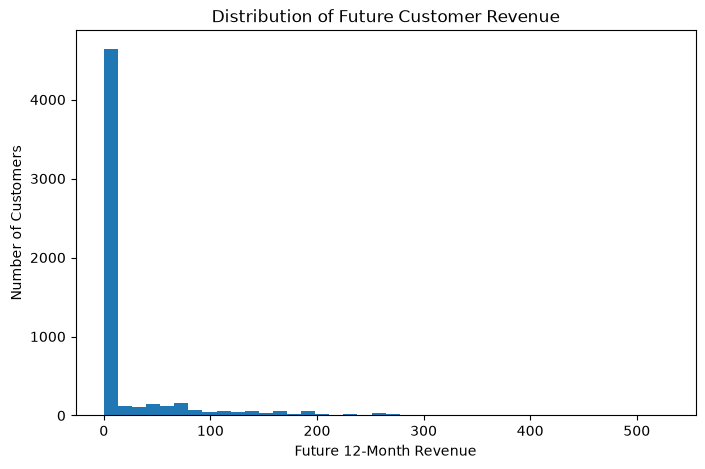

In [29]:
# Step-29 Analyze target distribution
import matplotlib.pyplot as plt

zero_revenue = (clv_dataset["future_revenue_12m"] == 0).sum()
positive_revenue = (clv_dataset["future_revenue_12m"] > 0).sum()

print("Zero revenue customers:", zero_revenue)
print("Positive revenue customers:", positive_revenue)

print("\nPercentage distribution:")
print(clv_dataset["future_revenue_12m"].eq(0).mean() * 100)
print(clv_dataset["future_revenue_12m"].gt(0).mean() * 100)

plt.figure(figsize=(8, 5))
plt.hist(clv_dataset["future_revenue_12m"], bins=40)
plt.xlabel("Future 12-Month Revenue")
plt.ylabel("Number of Customers")
plt.title("Distribution of Future Customer Revenue")
plt.show()

In [30]:
# Step 30 — Analyze positive revenue customers
positive_revenue = clv_dataset.loc[
    clv_dataset["future_revenue_12m"] > 0,
    "future_revenue_12m"
]

print("Positive revenue customers:", len(positive_revenue))

print("\nPositive revenue statistics:")
display(positive_revenue.describe())

print("\nRevenue percentiles:")
display(
    positive_revenue.quantile(
        [0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Positive revenue customers: 1233

Positive revenue statistics:


count    1233.000000
mean       93.915515
std        71.322114
min         6.990000
25%        41.940000
50%        76.890000
75%       139.410000
max       528.770000
Name: future_revenue_12m, dtype: float64


Revenue percentiles:


0.10     20.97
0.25     41.94
0.50     76.89
0.75    139.41
0.90    185.88
0.95    230.88
0.99    275.88
Name: future_revenue_12m, dtype: float64

In [31]:
# Step 31 — Prepare the two-stage targets
clv_dataset["will_generate_revenue"] = (
    clv_dataset["future_revenue_12m"] > 0
).astype(int)

print("Classification target distribution:")
display(clv_dataset["will_generate_revenue"].value_counts())

print("\nClassification target percentages:")
display(
    clv_dataset["will_generate_revenue"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nRegression dataset shape:")
print(
    clv_dataset[
        clv_dataset["future_revenue_12m"] > 0
    ].shape
)

Classification target distribution:


will_generate_revenue
0    4597
1    1233
Name: count, dtype: int64


Classification target percentages:


will_generate_revenue
0    78.85
1    21.15
Name: proportion, dtype: float64


Regression dataset shape:
(1233, 23)


In [32]:
# Step 32 — Prepare feature columns
excluded_columns = [
    "customer_id",
    "last_payment_date",
    "future_revenue_12m",
    "will_generate_revenue"
]

X = clv_dataset.drop(columns=excluded_columns)

y_classification = clv_dataset["will_generate_revenue"]
y_regression = clv_dataset["future_revenue_12m"]

print("Feature dataset shape:", X.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nClassification target shape:", y_classification.shape)
print("Regression target shape:", y_regression.shape)

print("\nFeature data types:")
display(X.dtypes)

Feature dataset shape: (5830, 19)

Feature columns:
['historical_payment_transactions', 'historical_successful_payments', 'historical_failed_payments', 'historical_revenue', 'historical_avg_payment', 'days_since_last_payment', 'total_subscriptions', 'unique_plans_used', 'average_monthly_price', 'maximum_monthly_price', 'minimum_monthly_price', 'auto_renew_subscription_count', 'age', 'gender', 'country', 'acquisition_channel', 'customer_segment', 'preferred_language', 'customer_tenure_days']

Classification target shape: (5830,)
Regression target shape: (5830,)

Feature data types:


historical_payment_transactions      int64
historical_successful_payments       int64
historical_failed_payments           int64
historical_revenue                 float64
historical_avg_payment             float64
days_since_last_payment              int64
total_subscriptions                  int64
unique_plans_used                    int64
average_monthly_price              float64
maximum_monthly_price              float64
minimum_monthly_price              float64
auto_renew_subscription_count        int64
age                                float64
gender                                 str
country                                str
acquisition_channel                    str
customer_segment                       str
preferred_language                     str
customer_tenure_days                 int64
dtype: object

In [33]:
# Step 33 — Check feature quality before splitting
numeric_features = X.select_dtypes(include=["int64", "float64"])

print("Numerical features:", numeric_features.shape[1])

print("\nMissing values:")
display(X.isnull().sum())

correlation_matrix = numeric_features.corr()

high_correlations = (
    correlation_matrix.where(
        np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
    )
    .stack()
    .reset_index()
)

high_correlations.columns = ["Feature 1", "Feature 2", "Correlation"]

display(
    high_correlations[
        high_correlations["Correlation"].abs() > 0.85
    ].sort_values(
        by="Correlation",
        key=abs,
        ascending=False
    )
)

Numerical features: 14

Missing values:


historical_payment_transactions      0
historical_successful_payments       0
historical_failed_payments           0
historical_revenue                   0
historical_avg_payment               0
days_since_last_payment              0
total_subscriptions                  0
unique_plans_used                    0
average_monthly_price                0
maximum_monthly_price                0
minimum_monthly_price                0
auto_renew_subscription_count        0
age                                239
gender                               0
country                            281
acquisition_channel                  0
customer_segment                     0
preferred_language                 185
customer_tenure_days                 0
dtype: int64

,Feature 1,Feature 2,Correlation
122,average_monthly_price,minimum_monthly_price,1.000000
136,maximum_monthly_price,minimum_monthly_price,1.000000
121,average_monthly_price,maximum_monthly_price,1.000000
83,days_since_last_payment,customer_tenure_days,0.986948
1,historical_payment_transactions,historical_successful_payments,0.959759
66,historical_avg_payment,minimum_monthly_price,0.939625
64,historical_avg_payment,average_monthly_price,0.939625
65,historical_avg_payment,maximum_monthly_price,0.939625


In [34]:
# Step 34 — Separate numerical and categorical features
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

Numerical features: 14
['historical_payment_transactions', 'historical_successful_payments', 'historical_failed_payments', 'historical_revenue', 'historical_avg_payment', 'days_since_last_payment', 'total_subscriptions', 'unique_plans_used', 'average_monthly_price', 'maximum_monthly_price', 'minimum_monthly_price', 'auto_renew_subscription_count', 'age', 'customer_tenure_days']

Categorical features: 5
['gender', 'country', 'acquisition_channel', 'customer_segment', 'preferred_language']


In [35]:
# Step 35 — Split the data into training and testing sets
from sklearn.model_selection import train_test_split

positive_mask = y_regression > 0

X_regression = X.loc[positive_mask].copy()
y_regression_positive = y_regression.loc[positive_mask].copy()

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X,
    y_classification,
    test_size=0.2,
    random_state=42,
    stratify=y_classification
)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_regression,
    y_regression_positive,
    test_size=0.2,
    random_state=42
)

print("CLASSIFICATION DATA")
print("Training:", X_train_cls.shape)
print("Testing:", X_test_cls.shape)

print("\nREGRESSION DATA")
print("Training:", X_train_reg.shape)
print("Testing:", X_test_reg.shape)

CLASSIFICATION DATA
Training: (4664, 19)
Testing: (1166, 19)

REGRESSION DATA
Training: (986, 19)
Testing: (247, 19)


In [36]:
# Step 36 - Classification Model Training
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)


In [37]:

%whos


Variable                                Type                Data/Info
---------------------------------------------------------------------
DecisionTreeClassifier                  ABCMeta             <class 'sklearn.tree._cla<...>.DecisionTreeClassifier'>
GradientBoostingClassifier              ABCMeta             <class 'sklearn.ensemble.<...>dientBoostingClassifier'>
LogisticRegression                      type                <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
RandomForestClassifier                  ABCMeta             <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
X                                       DataFrame           Shape: (5830, 19)
X_regression                            DataFrame           Shape: (1233, 19)
X_test_cls                              DataFrame           Shape: (1166, 19)
X_test_reg                              DataFrame           Shape: (247, 19)
X_train_cls                             DataFrame           Shape: (4664, 19)
X_train

In [38]:

categorical_cols = X_train_cls.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

print("\nUnique values:")
for col in categorical_cols:
    print(f"\n{col}:")
    print(X_train_cls[col].value_counts().head(10))


Categorical columns:
['gender', 'country', 'acquisition_channel', 'customer_segment', 'preferred_language']

Unique values:

gender:
gender
Female               2234
Male                 2213
Other                 136
Prefer not to say      81
Name: count, dtype: int64

country:
country
United States     839
India             737
United Kingdom    371
Canada            258
Brazil            229
Germany           214
France            195
Mexico            174
Japan             145
Philippines       141
Name: count, dtype: int64

acquisition_channel:
acquisition_channel
Organic Search              1057
Paid Social                  853
Referral                     614
App Store                    586
Email Campaign               466
Affiliate Partner            452
Partner Bundle (Telecom)     362
Direct                       274
Name: count, dtype: int64

customer_segment:
customer_segment
Individual          2537
Family              1159
Student              582
Corporate Bundle     38

In [39]:
# Import preprocessing libraries

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline


In [40]:
# Identify numerical columns

numerical_cols = X_train_cls.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

print("\nNumerical features:", len(numerical_cols))
print("Categorical features:", len(categorical_cols))


Numerical columns: ['historical_payment_transactions', 'historical_successful_payments', 'historical_failed_payments', 'historical_revenue', 'historical_avg_payment', 'days_since_last_payment', 'total_subscriptions', 'unique_plans_used', 'average_monthly_price', 'maximum_monthly_price', 'minimum_monthly_price', 'auto_renew_subscription_count', 'age', 'customer_tenure_days']
Categorical columns: ['gender', 'country', 'acquisition_channel', 'customer_segment', 'preferred_language']

Numerical features: 14
Categorical features: 5


In [41]:
from sklearn.impute import SimpleImputer

In [42]:

import pandas as pd
import numpy as np

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)


In [43]:
# Identify feature columns
categorical_cols = X_train_cls.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_cols = X_train_cls.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)


Categorical columns: ['gender', 'country', 'acquisition_channel', 'customer_segment', 'preferred_language']
Numerical columns: ['historical_payment_transactions', 'historical_successful_payments', 'historical_failed_payments', 'historical_revenue', 'historical_avg_payment', 'days_since_last_payment', 'total_subscriptions', 'unique_plans_used', 'average_monthly_price', 'maximum_monthly_price', 'minimum_monthly_price', 'auto_renew_subscription_count', 'age', 'customer_tenure_days']


In [44]:
# Create preprocessing pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [45]:
# Verify preprocessing

X_train_processed = preprocessor.fit_transform(X_train_cls)
X_test_processed = preprocessor.transform(X_test_cls)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("Missing values in training data:",
      np.isnan(X_train_processed.toarray() if hasattr(X_train_processed, "toarray")
               else X_train_processed).sum())


Training data shape: (4664, 63)
Testing data shape: (1166, 63)
Missing values in training data: 0


In [46]:
# Train classification models

classification_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

classification_results = {}
classification_trained_models = {}

for name, model in classification_models.items():

    model.fit(X_train_processed, y_train_cls)

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    classification_trained_models[name] = model

    classification_results[name] = {
        "Accuracy": accuracy_score(y_test_cls, y_pred),
        "Precision": precision_score(y_test_cls, y_pred, zero_division=0),
        "Recall": recall_score(y_test_cls, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test_cls, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test_cls, y_prob)
    }

    print(f"\n{'='*50}")
    print(name)
    print('='*50)
    print(classification_report(y_test_cls, y_pred))



Logistic Regression
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       919
           1       1.00      0.97      0.99       247

    accuracy                           0.99      1166
   macro avg       1.00      0.99      0.99      1166
weighted avg       0.99      0.99      0.99      1166


Decision Tree
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       919
           1       0.99      1.00      0.99       247

    accuracy                           1.00      1166
   macro avg       1.00      1.00      1.00      1166
weighted avg       1.00      1.00      1.00      1166


Random Forest
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       919
           1       0.99      1.00      1.00       247

    accuracy                           1.00      1166
   macro avg       1.00      1.00      1.00      1166
weighted avg       1.00

In [47]:

classification_results_df = pd.DataFrame(
    classification_results
).T.sort_values(
    by="F1 Score",
    ascending=False
)

display(classification_results_df.round(4))


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Gradient Boosting,0.9983,0.9920,1.0000,0.9960,1.0000
Random Forest,0.9983,0.9920,1.0000,0.9960,0.9999
Decision Tree,0.9974,0.9919,0.9960,0.9939,0.9969
Logistic Regression,0.9940,1.0000,0.9717,0.9856,0.9999


In [48]:
# Verify data leakage

print("Classification feature columns:")
print(X_train_cls.columns.tolist())

print("\nTarget distribution:")
print(y_train_cls.value_counts())

print("\nTarget distribution (%):")
print((y_train_cls.value_counts(normalize=True) * 100).round(2))

print("\nMissing values in original training features:")
print(X_train_cls.isnull().sum().sum())


Classification feature columns:
['historical_payment_transactions', 'historical_successful_payments', 'historical_failed_payments', 'historical_revenue', 'historical_avg_payment', 'days_since_last_payment', 'total_subscriptions', 'unique_plans_used', 'average_monthly_price', 'maximum_monthly_price', 'minimum_monthly_price', 'auto_renew_subscription_count', 'age', 'gender', 'country', 'acquisition_channel', 'customer_segment', 'preferred_language', 'customer_tenure_days']

Target distribution:
will_generate_revenue
0    3678
1     986
Name: count, dtype: int64

Target distribution (%):
will_generate_revenue
0    78.86
1    21.14
Name: proportion, dtype: float64

Missing values in original training features:
556


In [49]:

print("Historical Revenue by Target:")

print(
    clv_dataset.groupby("will_generate_revenue")[
        "historical_revenue"
    ].describe()
)

print("\nTarget vs Historical Payment Transactions:")

print(
    clv_dataset.groupby("will_generate_revenue")[
        "historical_payment_transactions"
    ].describe()
)

print("\nTarget vs Historical Successful Payments:")

print(
    clv_dataset.groupby("will_generate_revenue")[
        "historical_successful_payments"
    ].describe()
)


Historical Revenue by Target:
                        count        mean        std    min    25%     50%  \
will_generate_revenue                                                        
0                      4597.0  193.731901  94.215889  62.91  97.86  209.12   
1                      1233.0   95.656683  75.465949   0.00  41.94   76.89   

                          75%     max  
will_generate_revenue                  
0                      232.35  629.93  
1                      139.41  505.78  

Target vs Historical Payment Transactions:
                        count       mean       std   min   25%   50%   75%  \
will_generate_revenue                                                        
0                      4597.0  14.998695  0.036108  14.0  15.0  15.0  15.0   
1                      1233.0   7.469586  3.974871   1.0   4.0   7.0  11.0   

                        max  
will_generate_revenue        
0                      15.0  
1                      14.0  

Target vs Historica

In [50]:
# Check the target creation logic

print("CLV target creation details:")

print(clv_target.head(10))

print("\nTarget column information:")
print(clv_target.info())

print("\nTarget correlations:")
print(
    clv_dataset[
        ["historical_revenue",
         "historical_payment_transactions",
         "historical_successful_payments",
         "will_generate_revenue"]
    ].corr(numeric_only=True)
)


CLV target creation details:
  customer_id  future_revenue_12m
0  CUST000001                0.00
1  CUST000003                0.00
2  CUST000004                0.00
3  CUST000008              232.35
4  CUST000009                0.00
5  CUST000010                0.00
6  CUST000011                0.00
7  CUST000012               30.98
8  CUST000013               13.98
9  CUST000017                0.00

Target column information:
<class 'pandas.DataFrame'>
RangeIndex: 5830 entries, 0 to 5829
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         5830 non-null   str    
 1   future_revenue_12m  5830 non-null   float64
dtypes: float64(1), str(1)
memory usage: 148.9 KB
None

Target correlations:
                                 historical_revenue  \
historical_revenue                         1.000000   
historical_payment_transactions            0.467558   
historical_successful_payments      

In [51]:
clv_dataset["will_generate_revenue"] = (
    clv_dataset["future_revenue_12m"] > 0
).astype(int)

In [52]:

print("Historical feature dataset shape:")
print(clv_features.shape)

print("\nHistorical feature columns:")
print(clv_features.columns.tolist())

print("\nCLV dataset sample:")
display(clv_dataset.head())

print("\nHistorical payment date range:")
print(payments["payment_date"].min())
print(payments["payment_date"].max())


Historical feature dataset shape:
(5830, 21)

Historical feature columns:
['customer_id', 'historical_payment_transactions', 'historical_successful_payments', 'historical_failed_payments', 'historical_revenue', 'historical_avg_payment', 'last_payment_date', 'days_since_last_payment', 'total_subscriptions', 'unique_plans_used', 'average_monthly_price', 'maximum_monthly_price', 'minimum_monthly_price', 'auto_renew_subscription_count', 'age', 'gender', 'country', 'acquisition_channel', 'customer_segment', 'preferred_language', 'customer_tenure_days']

CLV dataset sample:


,customer_id,historical_payment_transactions,historical_successful_payments,historical_failed_payments,historical_revenue,historical_avg_payment,last_payment_date,days_since_last_payment,total_subscriptions,unique_plans_used,...,auto_renew_subscription_count,age,gender,country,acquisition_channel,customer_segment,preferred_language,customer_tenure_days,future_revenue_12m,will_generate_revenue
0,CUST000001,15,15,0,333.35,22.223333,2023-06-24,342,1,1,...,1,43.0,Other,United States,Organic Search,Student,English,762,0.00,0
1,CUST000003,15,15,0,344.85,22.990000,2021-02-07,1209,1,1,...,1,17.0,Female,Germany,Referral,Individual,Indonesian,1629,0.00,0
2,CUST000004,15,14,1,97.86,6.990000,2020-03-23,1530,1,1,...,0,39.0,Male,Australia,Paid Social,Individual,Tagalog,1950,0.00,0
3,CUST000008,10,10,0,154.90,15.490000,2024-05-17,14,1,1,...,1,23.0,Female,Japan,App Store,Individual,Korean,284,232.35,1
4,CUST000009,15,13,2,185.88,14.298462,2021-01-11,1236,1,1,...,1,NaN,Other,Germany,Affiliate Partner,Individual,Hindi,1656,0.00,0



Historical payment date range:
2019-01-01 00:00:00
2026-05-31 00:00:00


In [53]:
# Run this leakage verification

historical_cutoff = pd.Timestamp("2024-05-31")
future_start = pd.Timestamp("2024-06-01")
future_end = pd.Timestamp("2025-05-31")

print("HISTORICAL FEATURE VERIFICATION")

print("\nLatest historical payment date:")
print(clv_features["last_payment_date"].max())

print("\nHistorical records after cutoff:")
print(
    (clv_features["last_payment_date"] > historical_cutoff).sum()
)

print("\nPayment transactions after historical cutoff:")
print(
    (payments["payment_date"] > historical_cutoff).sum()
)

print("\nPayment transactions in future target period:")
print(
    payments["payment_date"].between(
        future_start, future_end
    ).sum()
)

print("\nHistorical feature missing values:")
print(clv_features.isnull().sum())


HISTORICAL FEATURE VERIFICATION

Latest historical payment date:
2024-05-31 00:00:00

Historical records after cutoff:
0

Payment transactions after historical cutoff:
32576

Payment transactions in future target period:
16432

Historical feature missing values:
customer_id                          0
historical_payment_transactions      0
historical_successful_payments       0
historical_failed_payments           0
historical_revenue                   0
historical_avg_payment               0
last_payment_date                    0
days_since_last_payment              0
total_subscriptions                  0
unique_plans_used                    0
average_monthly_price                0
maximum_monthly_price                0
minimum_monthly_price                0
auto_renew_subscription_count        0
age                                239
gender                               0
country                            281
acquisition_channel                  0
customer_segment                   

In [54]:
# Check the target period
future_payments = payments[
    payments["payment_date"].between(
        future_start, future_end
    )
]

print("Future payment date range:")
print(future_payments["payment_date"].min())
print(future_payments["payment_date"].max())

print("\nFuture payment status:")
print(future_payments["payment_status"].value_counts())

print("\nCustomers with future payments:")
print(future_payments["customer_id"].nunique())


Future payment date range:
2024-06-01 00:00:00
2025-05-31 00:00:00

Future payment status:
payment_status
Success    15357
Failed      1075
Name: count, dtype: int64

Customers with future payments:
2330


In [55]:

future_success = future_payments[
    future_payments["payment_status"] == "Success"
]

future_revenue_check = (
    future_success.groupby("customer_id")["amount"]
    .sum()
    .reset_index(name="future_revenue_check")
)

print("Customers with successful future payments:",
      future_success["customer_id"].nunique())

print("Customers with positive future revenue:",
      (future_revenue_check["future_revenue_check"] > 0).sum())

print("\nFuture revenue distribution:")
print(future_revenue_check["future_revenue_check"].describe())

print("\nZero revenue customers with successful payments:")
print((future_revenue_check["future_revenue_check"] == 0).sum())


Customers with successful future payments: 2316
Customers with positive future revenue: 2315

Future revenue distribution:
count    2316.000000
mean       90.696891
std        68.796843
min         0.000000
25%        41.940000
50%        69.900000
75%       137.940000
max       528.770000
Name: future_revenue_check, dtype: float64

Zero revenue customers with successful payments:
1


In [56]:

print("Target positive customers:",
      (clv_target["future_revenue_12m"] > 0).sum())

print("\nRecalculated positive customers:",
      (future_revenue_check["future_revenue_check"] > 0).sum())

print("\nOriginal target revenue total:",
      clv_target["future_revenue_12m"].sum())

print("\nRecalculated revenue total:",
      future_revenue_check["future_revenue_check"].sum())

print("\nOriginal target shape:", clv_target.shape)
print("Recalculated target shape:", future_revenue_check.shape)


Target positive customers: 1233

Recalculated positive customers: 2315

Original target revenue total: 115797.83000000002

Recalculated revenue total: 210054.0

Original target shape: (5830, 2)
Recalculated target shape: (2316, 2)


In [57]:

original_ids = set(clv_target["customer_id"])
recalculated_ids = set(future_revenue_check["customer_id"])

print("Original target customers:", len(original_ids))
print("Recalculated customers:", len(recalculated_ids))

print("Common customers:", len(original_ids & recalculated_ids))
print("Only in original:", len(original_ids - recalculated_ids))
print("Only in recalculated:", len(recalculated_ids - original_ids))


Original target customers: 5830
Recalculated customers: 2316
Common customers: 1233
Only in original: 4597
Only in recalculated: 1083


In [58]:
# Verify customer-level revenue matching

target_comparison = clv_target.merge(
    future_revenue_check,
    on="customer_id",
    how="left"
)

target_comparison["future_revenue_check"] = (
    target_comparison["future_revenue_check"].fillna(0)
)

target_comparison["revenue_difference"] = (
    target_comparison["future_revenue_12m"]
    - target_comparison["future_revenue_check"]
)

print("Customer-level target verification")

print("\nOriginal positive customers:",
      (target_comparison["future_revenue_12m"] > 0).sum())

print("\nRecalculated positive customers:",
      (target_comparison["future_revenue_check"] > 0).sum())

print("\nMatching revenue records:",
      (target_comparison["revenue_difference"].abs() < 0.01).sum())

print("\nMismatched revenue records:",
      (target_comparison["revenue_difference"].abs() >= 0.01).sum())

print("\nComparison sample:")
display(target_comparison.head(15))


Customer-level target verification

Original positive customers: 1233

Recalculated positive customers: 1233

Matching revenue records: 5830

Mismatched revenue records: 0

Comparison sample:


,customer_id,future_revenue_12m,future_revenue_check,revenue_difference
0,CUST000001,0.00,0.00,0.0
1,CUST000003,0.00,0.00,0.0
2,CUST000004,0.00,0.00,0.0
3,CUST000008,232.35,232.35,0.0
4,CUST000009,0.00,0.00,0.0
5,CUST000010,0.00,0.00,0.0
6,CUST000011,0.00,0.00,0.0
7,CUST000012,30.98,30.98,0.0
8,CUST000013,13.98,13.98,0.0
9,CUST000017,0.00,0.00,0.0


In [59]:
# Historical feature verification

historical_cutoff = pd.Timestamp("2024-05-31")

print("Latest historical payment date:")
print(clv_features["last_payment_date"].max())

print("\nHistorical feature dates after cutoff:")
print(
    (clv_features["last_payment_date"] > historical_cutoff).sum()
)

print("\nHistorical feature date range:")
print(clv_features["last_payment_date"].min())
print(clv_features["last_payment_date"].max())

print("\nHistorical missing values:")
display(
    clv_features.isnull().sum().sort_values(ascending=False)
)


Latest historical payment date:
2024-05-31 00:00:00

Historical feature dates after cutoff:
0

Historical feature date range:
2020-02-25 00:00:00
2024-05-31 00:00:00

Historical missing values:


country                            281
age                                239
preferred_language                 185
historical_payment_transactions      0
customer_id                          0
historical_revenue                   0
historical_failed_payments           0
historical_successful_payments       0
historical_avg_payment               0
unique_plans_used                    0
last_payment_date                    0
days_since_last_payment              0
total_subscriptions                  0
minimum_monthly_price                0
maximum_monthly_price                0
average_monthly_price                0
auto_renew_subscription_count        0
gender                               0
acquisition_channel                  0
customer_segment                     0
customer_tenure_days                 0
dtype: int64

In [60]:
# Recalculate historical payment features independently

historical_cutoff = pd.Timestamp("2024-05-31")

historical_payments = payments[
    payments["payment_date"] <= historical_cutoff
].copy()

historical_summary = (
    historical_payments.groupby("customer_id")
    .agg(
        historical_payment_transactions=("payment_id", "count"),
        historical_successful_payments=(
            "payment_status",
            lambda x: (x == "Success").sum()
        ),
        historical_failed_payments=(
            "payment_status",
            lambda x: (x == "Failed").sum()
        ),
        historical_revenue=(
            "amount",
            lambda x: x[
                historical_payments.loc[x.index, "payment_status"] == "Success"
            ].sum()
        ),
        historical_avg_payment=(
            "amount",
            lambda x: x[
                historical_payments.loc[x.index, "payment_status"] == "Success"
            ].mean()
        )
    )
    .reset_index()
)

print("Historical payment summary shape:")
print(historical_summary.shape)

print("\nHistorical payment date range:")
print(historical_payments["payment_date"].min())
print(historical_payments["payment_date"].max())

display(historical_summary.head())


Historical payment summary shape:
(5830, 6)

Historical payment date range:
2019-01-01 00:00:00
2024-05-31 00:00:00


,customer_id,historical_payment_transactions,historical_successful_payments,historical_failed_payments,historical_revenue,historical_avg_payment
0,CUST000001,15,15,0,333.35,22.223333
1,CUST000003,15,15,0,344.85,22.990000
2,CUST000004,15,14,1,97.86,6.990000
3,CUST000008,10,10,0,154.90,15.490000
4,CUST000009,15,13,2,185.88,14.298462


In [61]:
# Compare original and recalculated features

comparison = clv_features.merge(
    historical_summary,
    on="customer_id",
    how="left",
    suffixes=("_original", "_recalculated")
)

comparison_columns = [
    "historical_payment_transactions",
    "historical_successful_payments",
    "historical_failed_payments",
    "historical_revenue",
    "historical_avg_payment"
]

for col in comparison_columns:
    original = comparison[f"{col}_original"].fillna(0)
    recalculated = comparison[f"{col}_recalculated"].fillna(0)

    matches = np.isclose(
        original,
        recalculated,
        rtol=1e-5,
        atol=0.01
    )

    print(f"{col}: {matches.sum()} / {len(matches)} matching")


historical_payment_transactions: 5830 / 5830 matching
historical_successful_payments: 5830 / 5830 matching
historical_failed_payments: 5830 / 5830 matching
historical_revenue: 5830 / 5830 matching
historical_avg_payment: 5830 / 5830 matching


In [62]:

mismatch_records = comparison.copy()

for col in comparison_columns:
    mismatch_records[f"{col}_match"] = np.isclose(
        mismatch_records[f"{col}_original"].fillna(0),
        mismatch_records[f"{col}_recalculated"].fillna(0),
        rtol=1e-5,
        atol=0.01
    )

mismatched = mismatch_records[
    ~mismatch_records[
        [f"{col}_match" for col in comparison_columns]
    ].all(axis=1)
]

print("Total mismatched customers:", len(mismatched))

display(mismatched.head(20))


Total mismatched customers: 0


,customer_id,historical_payment_transactions_original,historical_successful_payments_original,historical_failed_payments_original,historical_revenue_original,historical_avg_payment_original,last_payment_date,days_since_last_payment,total_subscriptions,unique_plans_used,...,historical_payment_transactions_recalculated,historical_successful_payments_recalculated,historical_failed_payments_recalculated,historical_revenue_recalculated,historical_avg_payment_recalculated,historical_payment_transactions_match,historical_successful_payments_match,historical_failed_payments_match,historical_revenue_match,historical_avg_payment_match


In [63]:
# Check the index and columns
print("X columns:")
print(X.columns.tolist())

print("\nX index name:")
print(X.index.name)

print("\nCLV target columns:")
print(clv_target.columns.tolist())

print("\nCLV target index name:")
print(clv_target.index.name)

X columns:
['historical_payment_transactions', 'historical_successful_payments', 'historical_failed_payments', 'historical_revenue', 'historical_avg_payment', 'days_since_last_payment', 'total_subscriptions', 'unique_plans_used', 'average_monthly_price', 'maximum_monthly_price', 'minimum_monthly_price', 'auto_renew_subscription_count', 'age', 'gender', 'country', 'acquisition_channel', 'customer_segment', 'preferred_language', 'customer_tenure_days']

X index name:
None

CLV target columns:
['customer_id', 'future_revenue_12m']

CLV target index name:
None


In [64]:
feature_target_check = clv_features.merge(
    clv_target,
    on="customer_id",
    how="inner"
)

print("Merged dataset shape:", feature_target_check.shape)

correlations = (
    feature_target_check
    .select_dtypes(include="number")
    .corr()["future_revenue_12m"]
    .drop("future_revenue_12m")
    .sort_values(key=abs, ascending=False)
)

display(correlations.to_frame("Correlation"))

Merged dataset shape: (5830, 22)


,Correlation
historical_payment_transactions,-0.865588
historical_successful_payments,-0.828280
customer_tenure_days,-0.575159
days_since_last_payment,-0.463469
historical_revenue,-0.342435
historical_failed_payments,-0.197003
minimum_monthly_price,0.179594
maximum_monthly_price,0.179594
average_monthly_price,0.179594
historical_avg_payment,0.167115


In [65]:
# Check feature distributions by classification target

classification_analysis = clv_dataset.groupby(
    "will_generate_revenue"
).agg({
    "historical_payment_transactions": "mean",
    "historical_successful_payments": "mean",
    "historical_failed_payments": "mean",
    "historical_revenue": "mean",
    "historical_avg_payment": "mean",
    "days_since_last_payment": "mean",
    "customer_tenure_days": "mean",
    "total_subscriptions": "mean",
    "auto_renew_subscription_count": "mean"
})

display(classification_analysis.T.round(3))


will_generate_revenue,0,1
historical_payment_transactions,14.999,7.470
historical_successful_payments,14.028,6.944
historical_failed_payments,0.971,0.526
historical_revenue,193.732,95.657
historical_avg_payment,13.758,13.629
days_since_last_payment,766.677,14.715
customer_tenure_days,1186.638,208.802
total_subscriptions,1.068,1.019
auto_renew_subscription_count,0.870,0.847


In [66]:

print(
    clv_dataset.groupby("will_generate_revenue")[
        "historical_payment_transactions"
    ].describe()
)

print("\nUnique transaction counts by target:")

for target in [0, 1]:
    print(f"\nTarget {target}:")
    print(
        clv_dataset.loc[
            clv_dataset["will_generate_revenue"] == target,
            "historical_payment_transactions"
        ].value_counts().sort_index()
    )


                        count       mean       std   min   25%   50%   75%  \
will_generate_revenue                                                        
0                      4597.0  14.998695  0.036108  14.0  15.0  15.0  15.0   
1                      1233.0   7.469586  3.974871   1.0   4.0   7.0  11.0   

                        max  
will_generate_revenue        
0                      15.0  
1                      14.0  

Unique transaction counts by target:

Target 0:
historical_payment_transactions
14       6
15    4591
Name: count, dtype: int64

Target 1:
historical_payment_transactions
1      90
2      89
3      84
4      80
5      84
6      92
7     107
8      77
9      93
10    100
11     90
12     82
13     88
14     77
Name: count, dtype: int64


In [67]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

single_feature_model = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

single_feature_model.fit(
    X_train_cls[["historical_payment_transactions"]],
    y_train_cls
)

single_feature_pred = single_feature_model.predict(
    X_test_cls[["historical_payment_transactions"]]
)

print("Single Feature Model Performance")
print(classification_report(y_test_cls, single_feature_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test_cls, single_feature_pred))

print("\nDecision threshold:")
print(single_feature_model.tree_.threshold[0])

Single Feature Model Performance
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       919
           1       0.99      1.00      1.00       247

    accuracy                           1.00      1166
   macro avg       1.00      1.00      1.00      1166
weighted avg       1.00      1.00      1.00      1166

Confusion Matrix:
[[917   2]
 [  0 247]]

Decision threshold:
14.5


In [68]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

X_train_ablation = X_train_cls.drop(columns=["historical_payment_transactions"])
X_test_ablation = X_test_cls.drop(columns=["historical_payment_transactions"])

categorical_cols_ablation = [
    "gender",
    "country",
    "acquisition_channel",
    "customer_segment",
    "preferred_language"
]

numerical_cols_ablation = [
    col for col in X_train_ablation.columns
    if col not in categorical_cols_ablation
]

def create_preprocessor():
    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", numerical_pipeline, numerical_cols_ablation),
        ("cat", categorical_pipeline, categorical_cols_ablation)
    ])

ablation_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

ablation_results = []

for name, model in ablation_models.items():
    pipeline = Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", model)
    ])

    pipeline.fit(X_train_ablation, y_train_cls)

    predictions = pipeline.predict(X_test_ablation)
    probabilities = pipeline.predict_proba(X_test_ablation)[:, 1]

    ablation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_cls, predictions),
        "Precision": precision_score(y_test_cls, predictions),
        "Recall": recall_score(y_test_cls, predictions),
        "F1 Score": f1_score(y_test_cls, predictions),
        "ROC-AUC": roc_auc_score(y_test_cls, probabilities)
    })

ablation_results_df = pd.DataFrame(ablation_results)
ablation_results_df = ablation_results_df.sort_values(
    by="ROC-AUC", ascending=False
)

display(ablation_results_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Gradient Boosting,0.9983,0.9920,1.0000,0.9960,1.0000
0,Logistic Regression,0.9923,1.0000,0.9636,0.9814,0.9999
2,Random Forest,0.9983,0.9920,1.0000,0.9960,0.9999
1,Decision Tree,0.9966,0.9919,0.9919,0.9919,0.9949


In [69]:

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

regression_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42,
        max_depth=10
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}


In [70]:

categorical_columns = X_train_reg.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Categorical columns:", categorical_columns)

print("\nCategorical data types:")
print(X_train_reg[categorical_columns].dtypes)


Categorical columns: ['gender', 'country', 'acquisition_channel', 'customer_segment', 'preferred_language']

Categorical data types:
gender                 str
country                str
acquisition_channel    str
customer_segment       str
preferred_language     str
dtype: object


C:\Users\USER\AppData\Local\Temp\ipykernel_15456\2197021164.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train_reg.select_dtypes(


In [71]:
# Encode categorical features

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numerical_columns = X_train_reg.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            SimpleImputer(strategy="median"),
            numerical_columns
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_columns
        )
    ]
)


In [72]:
# Update model training

regression_results = []

for name, model in regression_models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])

    pipeline.fit(X_train_reg, y_train_reg)

    y_pred = pipeline.predict(X_test_reg)

    mae = mean_absolute_error(y_test_reg, y_pred)
    mse = mean_squared_error(y_test_reg, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_reg, y_pred)

    regression_results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

regression_results_df = pd.DataFrame(regression_results)

regression_results_df.sort_values(
    by="RMSE",
    ascending=True
)


,Model,MAE,MSE,RMSE,R2 Score
2,Random Forest,9.962456,609.236732,24.682721,0.897824
3,Gradient Boosting,10.488643,629.921991,25.098247,0.894354
1,Decision Tree,11.424371,791.756420,28.138167,0.867213
0,Linear Regression,13.889645,811.785136,28.491843,0.863854


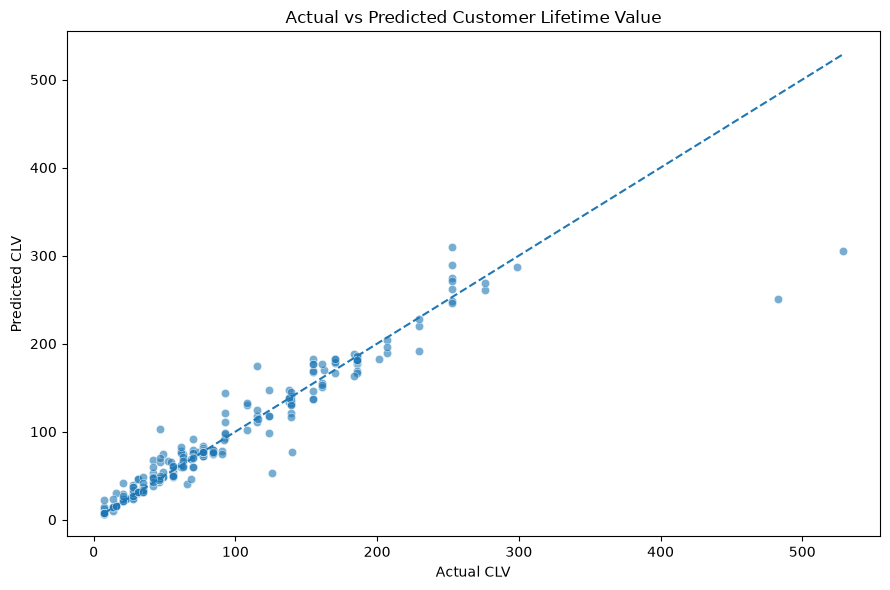

In [73]:
# Next: Actual vs Predicted CLV visualization

import matplotlib.pyplot as plt
import seaborn as sns

best_regression_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", regression_models["Random Forest"])
])

best_regression_pipeline.fit(X_train_reg, y_train_reg)

y_pred_rf = best_regression_pipeline.predict(X_test_reg)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=y_test_reg,
    y=y_pred_rf,
    alpha=0.6
)

min_value = min(y_test_reg.min(), y_pred_rf.min())
max_value = max(y_test_reg.max(), y_pred_rf.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual CLV")
plt.ylabel("Predicted CLV")
plt.title("Actual vs Predicted Customer Lifetime Value")

plt.tight_layout()
plt.show()


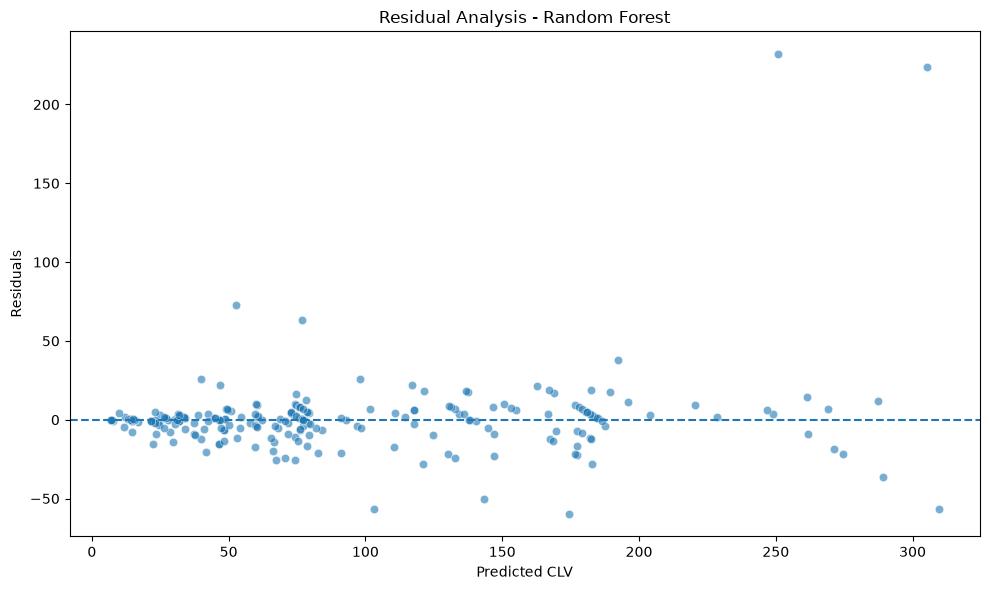

In [74]:
# Residual analysis

residuals = y_test_reg - y_pred_rf

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=y_pred_rf,
    y=residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted CLV")
plt.ylabel("Residuals")
plt.title("Residual Analysis - Random Forest")

plt.tight_layout()
plt.show()


In [75]:
# Identify the top 10 prediction errors

prediction_analysis = pd.DataFrame({
    "Actual_CLV": np.array(y_test_reg),
    "Predicted_CLV": y_pred_rf
})

prediction_analysis["Residual"] = (
    prediction_analysis["Actual_CLV"] -
    prediction_analysis["Predicted_CLV"]
)

prediction_analysis["Absolute_Error"] = (
    prediction_analysis["Residual"].abs()
)

prediction_analysis = prediction_analysis.sort_values(
    by="Absolute_Error",
    ascending=False
)

prediction_analysis.head(10)


,Actual_CLV,Predicted_CLV,Residual,Absolute_Error
3,482.79,250.940686,231.849314,231.849314
114,528.77,305.090107,223.679893,223.679893
57,125.82,52.851643,72.968357,72.968357
11,139.80,76.649016,63.150984,63.150984
104,114.95,174.467442,-59.517442,59.517442
242,46.47,103.308343,-56.838343,56.838343
102,252.89,309.516168,-56.626168,56.626168
14,92.94,143.481562,-50.541562,50.541562
226,229.90,192.165711,37.734289,37.734289
222,252.89,289.337820,-36.447820,36.447820


In [76]:
# Investigate high-error customers

top_error_positions = prediction_analysis.head(10).index

high_error_features = X_test_reg.iloc[
    top_error_positions
].copy()

high_error_features["Actual_CLV"] = np.asarray(
    y_test_reg
)[top_error_positions]

high_error_features["Predicted_CLV"] = y_pred_rf[
    top_error_positions
]

high_error_features["Absolute_Error"] = (
    high_error_features["Actual_CLV"] -
    high_error_features["Predicted_CLV"]
).abs()

high_error_features


,historical_payment_transactions,historical_successful_payments,historical_failed_payments,historical_revenue,historical_avg_payment,days_since_last_payment,total_subscriptions,unique_plans_used,average_monthly_price,maximum_monthly_price,...,age,gender,country,acquisition_channel,customer_segment,preferred_language,customer_tenure_days,Actual_CLV,Predicted_CLV,Absolute_Error
238,4,4,0,91.96,22.990000,22,1,1,22.99,22.99,...,48.0,Male,Germany,Partner Bundle (Telecom),Individual,English,112,482.79,250.940686,231.849314
2617,2,2,0,45.98,22.990000,28,1,1,22.99,22.99,...,24.0,Female,Brazil,Partner Bundle (Telecom),Individual,English,58,528.77,305.090107,223.679893
218,7,7,0,65.71,9.387143,1,1,1,6.99,6.99,...,27.0,Male,India,Referral,Family,Indonesian,181,125.82,52.851643,72.968357
3361,1,1,0,6.99,6.990000,19,1,1,6.99,6.99,...,37.0,Female,United States,Email Campaign,Student,English,19,139.80,76.649016,63.150984
1617,9,9,0,206.91,22.990000,25,1,1,22.99,22.99,...,20.0,Female,India,Referral,Individual,Hindi,265,114.95,174.467442,59.517442
2515,10,10,0,154.90,15.490000,23,1,1,15.49,15.49,...,47.0,Female,Canada,App Store,Individual,Korean,293,46.47,103.308343,56.838343
3220,2,2,0,45.98,22.990000,3,1,1,22.99,22.99,...,NaN,Male,Australia,Organic Search,Individual,English,33,252.89,309.516168,56.626168
2173,9,7,2,108.43,15.490000,19,1,1,15.49,15.49,...,NaN,Female,Mexico,Email Campaign,Individual,English,259,92.94,143.481562,50.541562
4770,5,5,0,114.95,22.990000,17,1,1,22.99,22.99,...,50.0,Male,Argentina,Direct,Individual,Indonesian,137,229.90,192.165711,37.734289
2659,2,2,0,45.98,22.990000,28,1,1,22.99,22.99,...,32.0,Prefer not to say,United Kingdom,App Store,Corporate Bundle,Portuguese,58,252.89,289.337820,36.447820


In [77]:
# Investigate payment feature consistency

payment_check = X_train_reg[
    [
        "historical_payment_transactions",
        "historical_successful_payments",
        "historical_failed_payments",
        "historical_revenue",
        "historical_avg_payment"
    ]
].copy()

payment_check["Expected_Total_Payments"] = (
    payment_check["historical_successful_payments"] +
    payment_check["historical_failed_payments"]
)

payment_check["Transaction_Count_Difference"] = (
    payment_check["historical_payment_transactions"] -
    payment_check["Expected_Total_Payments"]
)

payment_check.describe()


,historical_payment_transactions,historical_successful_payments,historical_failed_payments,historical_revenue,historical_avg_payment,Expected_Total_Payments,Transaction_Count_Difference
count,986.000000,986.000000,986.000000,986.000000,986.000000,986.000000,986.0
mean,7.460446,6.930020,0.530426,97.165335,13.866049,7.460446,0.0
std,3.892588,3.700209,0.794388,76.119428,7.496801,3.892588,0.0
min,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.0
25%,4.000000,4.000000,0.000000,41.940000,6.990000,4.000000,0.0
50%,7.000000,7.000000,0.000000,76.890000,15.490000,7.000000,0.0
75%,11.000000,10.000000,1.000000,139.410000,15.490000,11.000000,0.0
max,14.000000,14.000000,4.000000,505.780000,80.465000,14.000000,0.0


In [78]:
# Investigate zero-revenue customers

zero_revenue_mask = (
    (X_train_reg["historical_revenue"] == 0) &
    (X_train_reg["historical_successful_payments"] > 0)
)

print(
    "Zero revenue with successful payments:",
    zero_revenue_mask.sum()
)

print(
    "\nZero revenue with no successful payments:",
    (
        (X_train_reg["historical_revenue"] == 0) &
        (X_train_reg["historical_successful_payments"] == 0)
    ).sum()
)


Zero revenue with successful payments: 0

Zero revenue with no successful payments: 6


In [79]:
# CLV target distribution

print("CLV Target Distribution")
print(y_train_reg.describe())

print("\nCLV Percentiles")

print(
    y_train_reg.quantile(
        [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nHigh-value customers")

print(
    "CLV above 200:",
    (y_train_reg > 200).sum()
)

print(
    "CLV above 300:",
    (y_train_reg > 300).sum()
)

print(
    "CLV above 400:",
    (y_train_reg > 400).sum()
)


CLV Target Distribution
count    986.000000
mean      95.033783
std       69.720797
min        6.990000
25%       46.102500
50%       76.890000
75%      139.410000
max      505.780000
Name: future_revenue_12m, dtype: float64

CLV Percentiles
0.25     46.1025
0.50     76.8900
0.75    139.4100
0.90    185.8800
0.95    231.7375
0.99    275.8800
Name: future_revenue_12m, dtype: float64

High-value customers
CLV above 200: 85
CLV above 300: 4
CLV above 400: 2


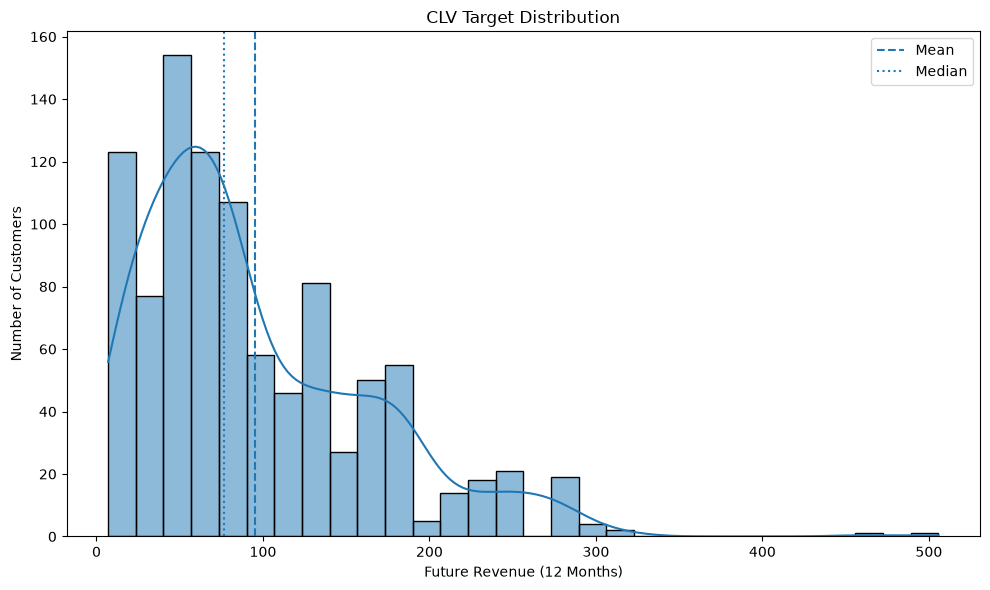

In [80]:
# Visualize the CLV distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    y_train_reg,
    bins=30,
    kde=True
)

plt.axvline(
    y_train_reg.mean(),
    linestyle="--",
    label="Mean"
)

plt.axvline(
    y_train_reg.median(),
    linestyle=":",
    label="Median"
)

plt.xlabel("Future Revenue (12 Months)")
plt.ylabel("Number of Customers")
plt.title("CLV Target Distribution")

plt.legend()
plt.tight_layout()
plt.show()


In [81]:
# Random Forest hyperparameter tuning

from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import numpy as np
import pandas as pd


In [82]:

import pandas as pd

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")


_: (8, 7)
__: (10, 22)
___: (10, 4)
df: (6260, 73)
payments: (110735, 8)
subscriptions: (8875, 10)
dataset: (8875, 10)
historical_payments: (78159, 8)
future_payments: (16432, 8)
future_revenue: (2316, 2)
clv_target: (5830, 2)
historical_subscriptions: (6165, 11)
active_subscriptions: (5830, 11)
future_subscriptions: (165, 10)
cohort_payments: (87450, 8)
historical_successful: (73049, 8)
future_successful: (8473, 8)
customer_payment_check: (8, 6)
historical_payment_features: (5830, 8)
historical_subscription_features: (5830, 7)
clv_features: (5830, 21)
customers: (8000, 12)
historical_customers: (5830, 13)
customer_features: (5830, 8)
clv_dataset: (5830, 23)
X: (5830, 19)
correlation_matrix: (14, 14)
high_correlations: (196, 3)
X_regression: (1233, 19)
X_train_cls: (4664, 19)
X_test_cls: (1166, 19)
X_train_reg: (986, 19)
X_test_reg: (247, 19)
classification_results_df: (4, 5)
future_success: (15357, 8)
future_revenue_check: (2316, 2)
target_comparison: (5830, 4)
historical_summary: (58

In [83]:

required_variables = [
    "X_train_reg",
    "X_test_reg",
    "y_train_reg",
    "y_test_reg",
    "preprocessor"
]

for variable in required_variables:
    print(variable, ":", variable in globals())


X_train_reg : True
X_test_reg : True
y_train_reg : True
y_test_reg : True
preprocessor : True


In [84]:
# check the shapes of the datasets and the type of the preprocessor
print("X_train_reg:", X_train_reg.shape)
print("X_test_reg:", X_test_reg.shape)
print("y_train_reg:", y_train_reg.shape)
print("y_test_reg:", y_test_reg.shape)

print("Preprocessor:", type(preprocessor).__name__)

X_train_reg: (986, 19)
X_test_reg: (247, 19)
y_train_reg: (986,)
y_test_reg: (247,)
Preprocessor: ColumnTransformer


In [85]:
# Continue – Random Forest hyperparameter tuning

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

print("Random Forest pipeline created successfully!")


Random Forest pipeline created successfully!


In [86]:
# Define search space

param_distributions = {
    "regressor__n_estimators": [200, 300, 400, 500],
    "regressor__max_depth": [None, 8, 10, 12, 15, 20],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [1, 2, 4],
    "regressor__max_features": [0.7, 1.0, "sqrt"]
}


In [87]:
# Cell 3 – Hyperparameter tuning

from sklearn.model_selection import RandomizedSearchCV, KFold

cv_strategy = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train_reg, y_train_reg)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV RMSE:")
print(-random_search.best_score_)


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'regressor__n_estimators': 500, 'regressor__min_samples_split': 5, 'regressor__min_samples_leaf': 4, 'regressor__max_features': 0.7, 'regressor__max_depth': 15}

Best CV RMSE:
19.92280391256565


In [88]:
# Evaluate tuned Random Forest

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

best_rf_model = random_search.best_estimator_

y_pred_tuned = best_rf_model.predict(X_test_reg)

tuned_mae = mean_absolute_error(
    y_test_reg, y_pred_tuned
)

tuned_rmse = np.sqrt(
    mean_squared_error(y_test_reg, y_pred_tuned)
)

tuned_r2 = r2_score(
    y_test_reg, y_pred_tuned
)

print("Tuned Random Forest Performance")
print("--------------------------------")
print(f"MAE: {tuned_mae:.4f}")
print(f"RMSE: {tuned_rmse:.4f}")
print(f"R2 Score: {tuned_r2:.4f}")


Tuned Random Forest Performance
--------------------------------
MAE: 9.4398
RMSE: 23.7401
R2 Score: 0.9055


In [89]:

comparison_df = pd.DataFrame([
    {
        "Model": "Baseline Random Forest",
        "MAE": 9.962456,
        "RMSE": 24.682721,
        "R2 Score": 0.897824
    },
    {
        "Model": "Tuned Random Forest",
        "MAE": tuned_mae,
        "RMSE": tuned_rmse,
        "R2 Score": tuned_r2
    }
])

comparison_df


,Model,MAE,RMSE,R2 Score
0,Baseline Random Forest,9.962456,24.682721,0.897824
1,Tuned Random Forest,9.439785,23.740102,0.905479


In [90]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        random_state=42
    ))
])

print("Gradient Boosting pipeline created!")

Gradient Boosting pipeline created!


In [91]:
gb_param_distributions = {
    "regressor__n_estimators": [100, 200, 300, 400],
    "regressor__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "regressor__max_depth": [2, 3, 4, 5],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [1, 2, 4],
    "regressor__subsample": [0.7, 0.8, 0.9, 1.0],
    "regressor__max_features": [None, "sqrt", 0.7]
}

In [92]:
from sklearn.model_selection import RandomizedSearchCV

gb_random_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_param_distributions,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

gb_random_search.fit(X_train_reg, y_train_reg)

print("Best Parameters:")
print(gb_random_search.best_params_)

print("\nBest CV RMSE:")
print(-gb_random_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'regressor__subsample': 0.7, 'regressor__n_estimators': 400, 'regressor__min_samples_split': 10, 'regressor__min_samples_leaf': 4, 'regressor__max_features': 0.7, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.01}

Best CV RMSE:
20.32466270504171


In [93]:
# Evaluate tuned Gradient Boosting

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

best_gb_model = gb_random_search.best_estimator_

y_pred_gb_tuned = best_gb_model.predict(X_test_reg)

gb_tuned_mae = mean_absolute_error(
    y_test_reg, y_pred_gb_tuned
)

gb_tuned_rmse = np.sqrt(
    mean_squared_error(y_test_reg, y_pred_gb_tuned)
)

gb_tuned_r2 = r2_score(
    y_test_reg, y_pred_gb_tuned
)

print("Tuned Gradient Boosting Performance")
print("-----------------------------------")
print(f"MAE: {gb_tuned_mae:.4f}")
print(f"RMSE: {gb_tuned_rmse:.4f}")
print(f"R2 Score: {gb_tuned_r2:.4f}")


Tuned Gradient Boosting Performance
-----------------------------------
MAE: 10.5523
RMSE: 24.8742
R2 Score: 0.8962


In [94]:
# Finalize and save the regression model

import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    best_rf_model,
    "models/clv_regression_model.pkl"
)

print("Regression model saved successfully!")


Regression model saved successfully!


In [95]:
# Next step – Save evaluation metrics
regression_metrics = {
    "model": "Tuned Random Forest",
    "MAE": tuned_mae,
    "RMSE": tuned_rmse,
    "R2_Score": tuned_r2,
    "best_parameters": random_search.best_params_,
    "cross_validation_RMSE": -random_search.best_score_
}

joblib.dump(
    regression_metrics,
    "models/clv_regression_metrics.pkl"
)

print("Regression metrics saved successfully!")

Regression metrics saved successfully!


In [96]:
# Recreate final comparison
final_model_comparison = pd.DataFrame([
    {
        "Model": "Baseline Random Forest",
        "MAE": 9.962456,
        "RMSE": 24.682721,
        "R2 Score": 0.897824
    },
    {
        "Model": "Tuned Random Forest",
        "MAE": tuned_mae,
        "RMSE": tuned_rmse,
        "R2 Score": tuned_r2
    },
    {
        "Model": "Baseline Gradient Boosting",
        "MAE": 10.488643,
        "RMSE": 25.098247,
        "R2 Score": 0.894354
    },
    {
        "Model": "Tuned Gradient Boosting",
        "MAE": gb_tuned_mae,
        "RMSE": gb_tuned_rmse,
        "R2 Score": gb_tuned_r2
    }
])

final_model_comparison = final_model_comparison.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

final_model_comparison


,Model,MAE,RMSE,R2 Score
0,Tuned Random Forest,9.439785,23.740102,0.905479
1,Baseline Random Forest,9.962456,24.682721,0.897824
2,Tuned Gradient Boosting,10.552310,24.874167,0.896232
3,Baseline Gradient Boosting,10.488643,25.098247,0.894354


In [97]:
# Save evaluation metrics

regression_metrics = {
    "selected_model": "Tuned Random Forest",
    "MAE": tuned_mae,
    "RMSE": tuned_rmse,
    "R2_Score": tuned_r2,
    "best_parameters": random_search.best_params_,
    "cross_validation_RMSE": -random_search.best_score_,
    "comparison": final_model_comparison.to_dict("records")
}

joblib.dump(
    regression_metrics,
    "models/clv_regression_metrics.pkl"
)

print("Regression metrics saved successfully!")


Regression metrics saved successfully!


In [98]:

print(os.listdir("models"))


['clv_classification_metrics.pkl', 'clv_classification_model.pkl', 'clv_regression_metrics.pkl', 'clv_regression_model.pkl']


In [99]:
# loading to joblib.pkl
import joblib

loaded_model = joblib.load("models/clv_regression_model.pkl")
loaded_metrics = joblib.load("models/clv_regression_metrics.pkl")

print("Model loaded:", type(loaded_model))
print("Selected model:", loaded_metrics["selected_model"])
print("MAE:", loaded_metrics["MAE"])
print("RMSE:", loaded_metrics["RMSE"])
print("R2 Score:", loaded_metrics["R2_Score"])

Model loaded: <class 'sklearn.pipeline.Pipeline'>
Selected model: Tuned Random Forest
MAE: 9.439785369220793
RMSE: 23.740102444573914
R2 Score: 0.9054787168843578


In [100]:
# Classification model finalization
[name for name in globals() if any(
    term in name.lower()
    for term in ["classification", "classifier", "best_rf", "best_gb", "y_pred"]
)]

['y_classification',
 'DecisionTreeClassifier',
 'RandomForestClassifier',
 'GradientBoostingClassifier',
 'classification_report',
 'classification_models',
 'classification_results',
 'classification_trained_models',
 'y_pred',
 'classification_results_df',
 'classification_analysis',
 'y_pred_rf',
 'best_rf_model',
 'y_pred_tuned',
 'best_gb_model',
 'y_pred_gb_tuned']

In [101]:
# Inspect the classification models
print("Classification trained models:")
for name, model in classification_trained_models.items():
    print(name, ":", type(model))

print("\nClassification results:")
display(classification_results_df)

Classification trained models:
Logistic Regression : <class 'sklearn.linear_model._logistic.LogisticRegression'>
Decision Tree : <class 'sklearn.tree._classes.DecisionTreeClassifier'>
Random Forest : <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Gradient Boosting : <class 'sklearn.ensemble._gb.GradientBoostingClassifier'>

Classification results:


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Gradient Boosting,0.998285,0.991968,1.000000,0.995968,0.999956
Random Forest,0.998285,0.991968,1.000000,0.995968,0.999903
Decision Tree,0.997427,0.991935,0.995951,0.993939,0.996888
Logistic Regression,0.993997,1.000000,0.971660,0.985626,0.999938


In [102]:
#  Check preprocessing
print("Classification target shape:", y_classification.shape)

print("\nClassification training variables:")
for name in ["X_train_class", "X_test_class", "X_train_cls", "X_test_cls"]:
    if name in globals():
        print(name, ":", globals()[name].shape)

print("\nModel feature count:")
for name, model in classification_trained_models.items():
    print(name, ":", getattr(model, "n_features_in_", "Not available"))

Classification target shape: (5830,)

Classification training variables:
X_train_cls : (4664, 19)
X_test_cls : (1166, 19)

Model feature count:
Logistic Regression : 63
Decision Tree : 63
Random Forest : 63
Gradient Boosting : 63


In [103]:
# Identify the classification preprocessor
from sklearn.pipeline import Pipeline

print("Available preprocessing-related variables:")

for name, obj in globals().copy().items():
    if any(term in name.lower() for term in ["preprocess", "encoder", "transformer"]):
        print(name, ":", type(obj))

print("\nClassification model details:")

for name, model in classification_trained_models.items():
    print(f"{name}: {type(model).__name__}")
    print("Input features:", model.n_features_in_)

Available preprocessing-related variables:
ColumnTransformer : <class 'abc.ABCMeta'>
OneHotEncoder : <class 'type'>
preprocessor : <class 'sklearn.compose._column_transformer.ColumnTransformer'>
create_preprocessor : <class 'function'>

Classification model details:
Logistic Regression: LogisticRegression
Input features: 63
Decision Tree: DecisionTreeClassifier
Input features: 63
Random Forest: RandomForestClassifier
Input features: 63
Gradient Boosting: GradientBoostingClassifier
Input features: 63


In [104]:
# Verify classification preprocessing
import inspect

print("Preprocessor function:")
print(inspect.getsource(create_preprocessor))

print("\nCurrent preprocessor:")
print(preprocessor)

print("\nIs preprocessor fitted?")
print(hasattr(preprocessor, "transformers_"))

if hasattr(preprocessor, "transformers_"):
    print("\nFitted transformers:")
    print(preprocessor.transformers_)

print("\nClassification training data type:")
print(type(X_train_cls))

Preprocessor function:
def create_preprocessor():
    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", numerical_pipeline, numerical_cols_ablation),
        ("cat", categorical_pipeline, categorical_cols_ablation)
    ])


Current preprocessor:
ColumnTransformer(transformers=[('num', SimpleImputer(strategy='median'),
                                 ['historical_payment_transactions',
                                  'historical_successful_payments',
                                  'historical_failed_payments',
                                  'historical_revenue',
                                  'historical_avg_payment',
                                  'days_since_last_payment',
     

In [105]:
# Verify the transformer against classification data
print("Numerical columns:", len(numerical_cols_ablation))
print("Categorical columns:", len(categorical_cols_ablation))

print("\nClassification feature columns:")
print(X_train_cls.columns.tolist())

print("\nPreprocessor numerical columns:")
print(preprocessor.transformers[0][2])

print("\nPreprocessor categorical columns:")
print(preprocessor.transformers[1][2])

print("\nTesting current preprocessor:")
try:
    transformed = preprocessor.transform(X_train_cls.head(5))
    print("Transformed shape:", transformed.shape)
except Exception as e:
    print("Transformation failed:", e)

Numerical columns: 13
Categorical columns: 5

Classification feature columns:
['historical_payment_transactions', 'historical_successful_payments', 'historical_failed_payments', 'historical_revenue', 'historical_avg_payment', 'days_since_last_payment', 'total_subscriptions', 'unique_plans_used', 'average_monthly_price', 'maximum_monthly_price', 'minimum_monthly_price', 'auto_renew_subscription_count', 'age', 'gender', 'country', 'acquisition_channel', 'customer_segment', 'preferred_language', 'customer_tenure_days']

Preprocessor numerical columns:
['historical_payment_transactions', 'historical_successful_payments', 'historical_failed_payments', 'historical_revenue', 'historical_avg_payment', 'days_since_last_payment', 'total_subscriptions', 'unique_plans_used', 'average_monthly_price', 'maximum_monthly_price', 'minimum_monthly_price', 'auto_renew_subscription_count', 'age', 'customer_tenure_days']

Preprocessor categorical columns:
['gender', 'country', 'acquisition_channel', 'custom

In [106]:
# Verify the fitted preprocessor
print("Preprocessor fitted:", hasattr(preprocessor, "transformers_"))

print("\nTransformed feature names:")
feature_names = preprocessor.get_feature_names_out()

print("Total:", len(feature_names))
print(feature_names)

print("\nClassification model classes:")
for name, model in classification_trained_models.items():
    print(name, ":", model.classes_)

Preprocessor fitted: True

Transformed feature names:
Total: 63
['num__historical_payment_transactions'
 'num__historical_successful_payments' 'num__historical_failed_payments'
 'num__historical_revenue' 'num__historical_avg_payment'
 'num__days_since_last_payment' 'num__total_subscriptions'
 'num__unique_plans_used' 'num__average_monthly_price'
 'num__maximum_monthly_price' 'num__minimum_monthly_price'
 'num__auto_renew_subscription_count' 'num__age'
 'num__customer_tenure_days' 'cat__gender_Female' 'cat__gender_Male'
 'cat__gender_Other' 'cat__gender_Prefer not to say'
 'cat__country_Argentina' 'cat__country_Australia' 'cat__country_Brazil'
 'cat__country_Canada' 'cat__country_France' 'cat__country_Germany'
 'cat__country_India' 'cat__country_Indonesia' 'cat__country_Italy'
 'cat__country_Japan' 'cat__country_Mexico' 'cat__country_Nigeria'
 'cat__country_Philippines' 'cat__country_Poland'
 'cat__country_South Africa' 'cat__country_South Korea'
 'cat__country_Spain' 'cat__country_Unit

In [107]:
# Test all four classifiers with the preprocessor
X_sample = X_test_cls.head(5)
X_sample_transformed = preprocessor.transform(X_sample)

print("Original shape:", X_sample.shape)
print("Transformed shape:", X_sample_transformed.shape)

for name, model in classification_trained_models.items():
    predictions = model.predict(X_sample_transformed)
    probabilities = model.predict_proba(X_sample_transformed)

    print(f"\n{name}")
    print("Predictions:", predictions)
    print("Probabilities shape:", probabilities.shape)

Original shape: (5, 19)
Transformed shape: (5, 63)

Logistic Regression
Predictions: [0 0 0 0 0]
Probabilities shape: (5, 2)

Decision Tree
Predictions: [0 0 0 0 0]
Probabilities shape: (5, 2)

Random Forest
Predictions: [0 0 0 0 0]
Probabilities shape: (5, 2)

Gradient Boosting
Predictions: [0 0 0 0 0]
Probabilities shape: (5, 2)


In [108]:
import pandas as pd

print("Actual test distribution:")
print(y_classification.loc[X_test_cls.index].value_counts())

print("\nPredicted test distribution:")

X_test_transformed = preprocessor.transform(X_test_cls)

for name, model in classification_trained_models.items():
    predictions = model.predict(X_test_transformed)

    print(f"\n{name}")
    print(pd.Series(predictions).value_counts())

Actual test distribution:
will_generate_revenue
0    919
1    247
Name: count, dtype: int64

Predicted test distribution:

Logistic Regression
0    1166
Name: count, dtype: int64

Decision Tree
0    1166
Name: count, dtype: int64

Random Forest
0    1166
Name: count, dtype: int64

Gradient Boosting
0    1166
Name: count, dtype: int64


In [109]:
# Save the classification pipeline

import os
import joblib
from sklearn.pipeline import Pipeline

os.makedirs("models", exist_ok=True)

classification_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classification_trained_models["Gradient Boosting"])
])

classification_metrics = classification_results_df.loc[
    "Gradient Boosting"
].to_dict()

joblib.dump(
    classification_pipeline,
    "models/clv_classification_model.pkl"
)

joblib.dump(
    classification_metrics,
    "models/clv_classification_metrics.pkl"
)

print("Classification model and metrics saved successfully!")
print(os.listdir("models"))


Classification model and metrics saved successfully!
['clv_classification_metrics.pkl', 'clv_classification_model.pkl', 'clv_regression_metrics.pkl', 'clv_regression_model.pkl']


In [110]:
# Generate customer-level CLV predictions
print("Available customer datasets:")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        if len(obj.columns) == 19:
            print(name, obj.shape)

Available customer datasets:
X (5830, 19)
X_regression (1233, 19)
X_train_cls (4664, 19)
X_test_cls (1166, 19)
X_train_reg (986, 19)
X_test_reg (247, 19)
X_sample (5, 19)


In [111]:
# Identify the customer ID column
for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame) and any(
        "customer_id" in str(col).lower() for col in obj.columns
    ):
        print(name, obj.shape)
        print(obj.columns.tolist())
        print()

df (6260, 73)
['customer_id', 'age', 'gender', 'country', 'city', 'acquisition_channel', 'customer_segment', 'preferred_language', 'tenure_days', 'total_viewing_sessions', 'total_watch_duration_minutes', 'average_watch_duration_minutes', 'average_completion_percentage', 'average_session_duration_minutes', 'unique_content_watched', 'active_viewing_days', 'days_since_last_viewing', 'has_viewing_activity', 'total_support_tickets', 'unique_issue_categories', 'most_common_issue_category', 'has_support_activity', 'total_payment_transactions', 'successful_payment_count', 'failed_payment_count', 'total_amount_paid', 'average_successful_payment_amount', 'payment_success_rate', 'unique_payment_methods', 'most_used_payment_method', 'days_since_last_successful_payment', 'has_successful_payment', 'total_feedback_count', 'average_feedback_rating', 'positive_feedback_count', 'neutral_feedback_count', 'negative_feedback_count', 'negative_feedback_rate', 'latest_feedback_rating', 'latest_feedback_senti

In [112]:
# Verify alignment
print("Feature columns match:",X.columns.equals(feature_target_check[X.columns].columns))

print("Feature values match:",X.equals(feature_target_check[X.columns]))

print("Indexes match:",X.index.equals(feature_target_check.index))

print("Customer IDs unique:",feature_target_check["customer_id"].is_unique)

print("Customer IDs missing:",feature_target_check["customer_id"].isna().sum())

Feature columns match: True
Feature values match: True
Indexes match: True
Customer IDs unique: True
Customer IDs missing: 0


In [113]:
# Generate customer-level predictions
print("Regression indexes match customer dataset:",X_regression.index.isin(feature_target_check.index).all())

print("Regression feature values match:",X_regression.equals(feature_target_check.loc[X_regression.index, X.columns]))

print("Regression customers:", len(X_regression))

Regression indexes match customer dataset: True
Regression feature values match: True
Regression customers: 1233


In [116]:
print("Available trained models:", classification_trained_models.keys())

Available trained models: dict_keys(['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting'])


In [119]:
print("X available:", "X" in globals())
print("X shape:", X.shape if "X" in globals() else "Not available")

X available: True
X shape: (5830, 19)


In [120]:
# Prepare segmentation features
segmentation_features = [
    "historical_payment_transactions",
    "historical_successful_payments",
    "historical_failed_payments",
    "historical_revenue",
    "historical_avg_payment",
    "days_since_last_payment",
    "total_subscriptions",
    "unique_plans_used",
    "average_monthly_price",
    "maximum_monthly_price",
    "minimum_monthly_price",
    "auto_renew_subscription_count",
    "customer_tenure_days"
]

segmentation_data = X[segmentation_features].copy()

print("Shape:", segmentation_data.shape)
print("Missing values:", segmentation_data.isnull().sum().sum())
print("Duplicate rows:", segmentation_data.duplicated().sum())

Shape: (5830, 13)
Missing values: 0
Duplicate rows: 520


In [121]:
# Scale the features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

segmentation_scaled = scaler.fit_transform(segmentation_data)

print("Scaled data shape:", segmentation_scaled.shape)
print("Feature means:", segmentation_scaled.mean(axis=0).round(2))
print("Feature standard deviations:", segmentation_scaled.std(axis=0).round(2))

Scaled data shape: (5830, 13)
Feature means: [ 0.  0.  0. -0. -0.  0. -0.  0.  0.  0.  0. -0. -0.]
Feature standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [122]:
# Find the optimal number of clusters
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(segmentation_scaled)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(silhouette_score(segmentation_scaled, labels))

cluster_results = pd.DataFrame({
    "Clusters": range(2, 11),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

print(cluster_results)

   Clusters       Inertia  Silhouette Score
0         2  54330.373347          0.305624
1         3  42138.550526          0.347613
2         4  32830.632934          0.376318
3         5  28452.614294          0.337108
4         6  25672.234771          0.347314
5         7  23666.580001          0.314847
6         8  21254.449673          0.307791
7         9  20082.505547          0.307699
8        10  18353.708436          0.316831


In [123]:
# Train the final K-Means model
kmeans_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_model.fit_predict(segmentation_scaled)

segmentation_data["customer_cluster"] = cluster_labels

print("Cluster distribution:")
print(segmentation_data["customer_cluster"].value_counts().sort_index())

print("\nCluster percentages:")
print(
    (segmentation_data["customer_cluster"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

Cluster distribution:
customer_cluster
0    2690
1     874
2    1949
3     317
Name: count, dtype: int64

Cluster percentages:
customer_cluster
0    46.14
1    14.99
2    33.43
3     5.44
Name: proportion, dtype: float64


In [124]:
cluster_profile = segmentation_data.groupby("customer_cluster")[segmentation_features].mean().round(2)

print(cluster_profile.T)

customer_cluster                       0       1        2        3
historical_payment_transactions    14.78    5.60    14.81    14.65
historical_successful_payments     13.93    5.19    13.69    13.70
historical_failed_payments          0.85    0.41     1.12     0.94
historical_revenue                259.36   67.96    97.95   191.07
historical_avg_payment             18.68   13.12     7.15    13.90
days_since_last_payment           693.97   14.72   717.74   832.97
total_subscriptions                 1.00    1.00     1.00     2.00
unique_plans_used                   1.00    1.00     1.00     1.73
average_monthly_price              18.22   12.95     6.99    13.63
maximum_monthly_price              18.22   12.95     6.99    13.63
minimum_monthly_price              18.22   12.95     6.99    13.63
auto_renew_subscription_count       0.82    0.84     0.82     1.66
customer_tenure_days             1107.40  152.60  1132.03  1242.37


In [125]:
# Create business-friendly segment labels
cluster_names = {
    0: "High Historical Spend - Inactive",
    1: "Recently Active Customers",
    2: "Low Spend - Inactive",
    3: "Multi-Subscription - Inactive"
}

segmentation_data["segment_name"] = segmentation_data["customer_cluster"].map(cluster_names)

print(segmentation_data["segment_name"].value_counts())

segment_name
High Historical Spend - Inactive    2690
Low Spend - Inactive                1949
Recently Active Customers            874
Multi-Subscription - Inactive        317
Name: count, dtype: int64


In [126]:
# Attach customer IDs and create the final dataset
customer_segments = pd.DataFrame({
    "customer_id": feature_target_check.loc[segmentation_data.index, "customer_id"].values,
    "customer_cluster": segmentation_data["customer_cluster"].values,
    "segment_name": segmentation_data["segment_name"].values
})

print("Shape:", customer_segments.shape)
print("Missing values:", customer_segments.isnull().sum().sum())
print(customer_segments.head())

Shape: (5830, 3)
Missing values: 0
  customer_id  customer_cluster                      segment_name
0  CUST000001                 0  High Historical Spend - Inactive
1  CUST000003                 0  High Historical Spend - Inactive
2  CUST000004                 2              Low Spend - Inactive
3  CUST000008                 1         Recently Active Customers
4  CUST000009                 0  High Historical Spend - Inactive


In [127]:
# Save the final segmentation dataset
customer_segments.to_csv("customer_segments.csv", index=False)

print("Saved: customer_segments.csv")

Saved: customer_segments.csv


In [128]:
import os

file_name = "customer_clv_predictions.csv"

print("File exists:", os.path.exists(file_name))

if os.path.exists(file_name):
    print("File size:", round(os.path.getsize(file_name) / 1024, 2), "KB")

File exists: True
File size: 119.85 KB
